In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
df = pd.read_excel("../data/transactions.xlsx")

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [3]:
print("Number of rows and columns:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

display(df.head(5))

Number of rows and columns: (541909, 8)

Column names:
['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 40.0+ MB


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [5]:
print("Number of rows and columns:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

display(df.head(5))

Number of rows and columns: (541909, 8)

Column names:
['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 40.0+ MB


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [6]:
missing_summary = pd.DataFrame({
    "Missing_Count": df.isnull().sum(),
    "Missing_Percentage": (
        df.isnull().mean() * 100
    ).round(2)
})

display(
    missing_summary.sort_values(
        "Missing_Percentage",
        ascending=False
    )
)

,Missing_Count,Missing_Percentage
CustomerID,135080,24.93
Description,1454,0.27
StockCode,0,0.00
InvoiceNo,0,0.00
Quantity,0,0.00
InvoiceDate,0,0.00
UnitPrice,0,0.00
Country,0,0.00


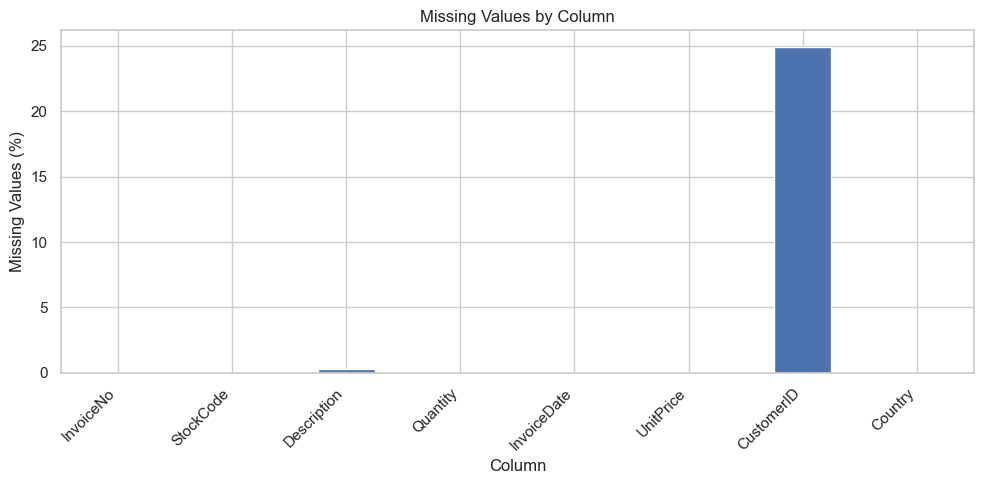

In [7]:
missing_summary["Missing_Percentage"].plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Missing Values by Column")
plt.xlabel("Column")
plt.ylabel("Missing Values (%)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [8]:
display(
    df[["Quantity", "UnitPrice"]].describe()
)

,Quantity,UnitPrice
count,541909.000000,541909.000000
mean,9.552250,4.611114
std,218.081158,96.759853
min,-80995.000000,-11062.060000
25%,1.000000,1.250000
50%,3.000000,2.080000
75%,10.000000,4.130000
max,80995.000000,38970.000000


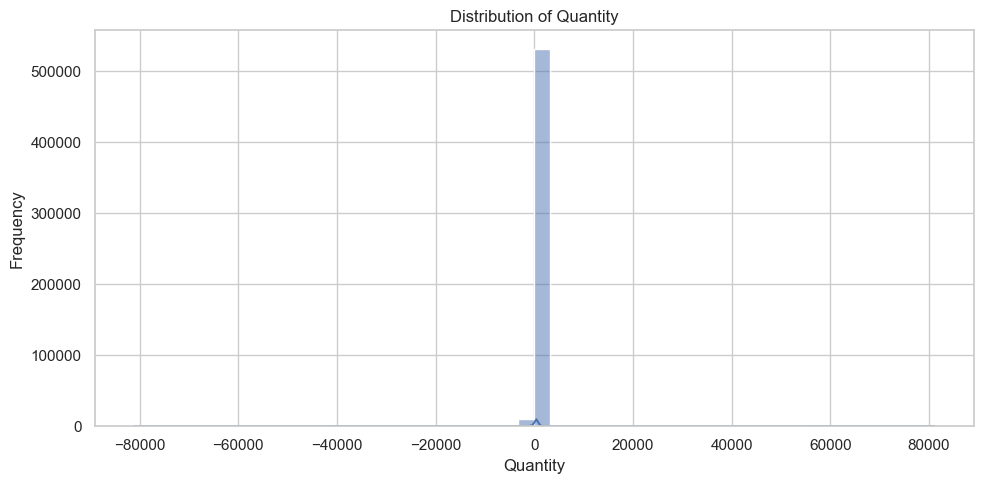

In [9]:
plt.figure(figsize=(10, 5))

sns.histplot(
    df["Quantity"].dropna(),
    bins=50,
    kde=True
)

plt.title("Distribution of Quantity")
plt.xlabel("Quantity")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

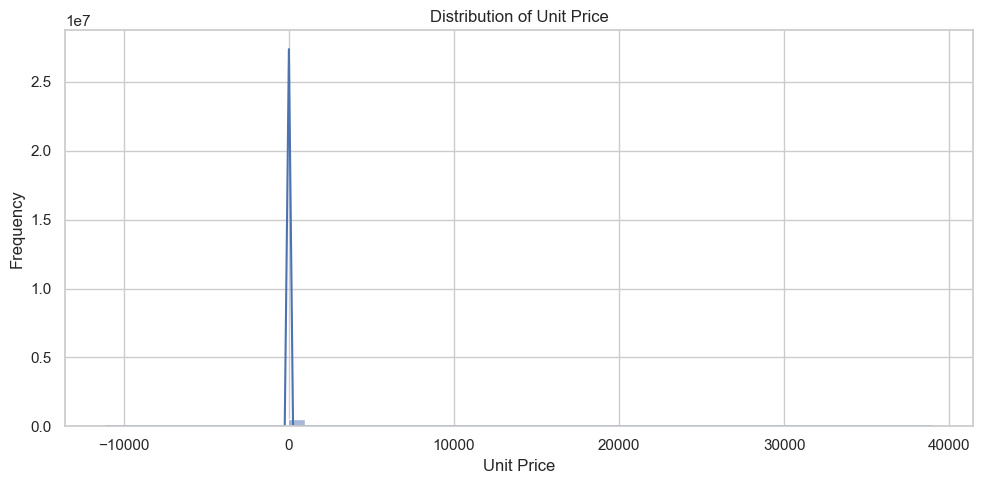

In [10]:
plt.figure(figsize=(10, 5))

sns.histplot(
    df["UnitPrice"].dropna(),
    bins=50,
    kde=True
)

plt.title("Distribution of Unit Price")
plt.xlabel("Unit Price")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

In [11]:
eda_df = df.copy()

eda_df["Revenue"] = (
    eda_df["Quantity"] * eda_df["UnitPrice"]
)

numeric_df = eda_df[
    ["Quantity", "UnitPrice", "Revenue"]
].dropna()

correlation_matrix = numeric_df.corr()

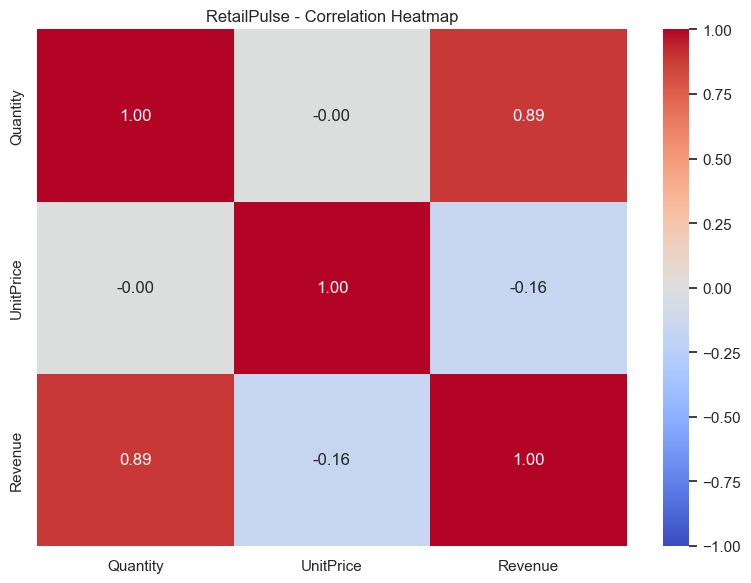

In [12]:
plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("RetailPulse - Correlation Heatmap")
plt.tight_layout()
plt.show()

In [13]:
from pathlib import Path

output_dir = Path("../outputs")
output_dir.mkdir(parents=True, exist_ok=True)

missing_summary.to_csv(
    output_dir / "day1_missing_values.csv"
)

correlation_matrix.to_csv(
    output_dir / "day1_correlation_matrix.csv"
)

print("Day 1 completed: EDA outputs saved!")

Day 1 completed: EDA outputs saved!


In [14]:
print("Duplicate rows:", df.duplicated().sum())

print("\nMissing values:")
display(df.isnull().sum())

print("\nNon-positive quantities:", (df["Quantity"] <= 0).sum())
print("Non-positive unit prices:", (df["UnitPrice"] <= 0).sum())

print("\nInvoice numbers starting with C:")
print(df["InvoiceNo"].astype(str).str.startswith("C").sum())

Duplicate rows: 5268

Missing values:


InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64


Non-positive quantities: 10624
Non-positive unit prices: 2517

Invoice numbers starting with C:
9288


In [15]:
df_clean = df.copy()

# Remove exact duplicate rows
df_clean = df_clean.drop_duplicates().copy()

# Convert columns to the correct data types
df_clean["InvoiceDate"] = pd.to_datetime(
    df_clean["InvoiceDate"], errors="coerce"
)

df_clean["Quantity"] = pd.to_numeric(
    df_clean["Quantity"], errors="coerce"
)

df_clean["UnitPrice"] = pd.to_numeric(
    df_clean["UnitPrice"], errors="coerce"
)

# Remove rows missing essential transaction information
df_clean = df_clean.dropna(
    subset=["InvoiceNo", "InvoiceDate", "Quantity", "UnitPrice"]
).copy()

# Create revenue for the retained transaction records
df_clean["Revenue"] = (
    df_clean["Quantity"] * df_clean["UnitPrice"]
)

print("Original rows:", len(df))
print("Cleaned rows:", len(df_clean))
print("Remaining duplicates:", df_clean.duplicated().sum())

display(df_clean.head())

Original rows: 541909
Cleaned rows: 536641
Remaining duplicates: 0


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34


In [16]:
sales_df = df_clean[
    (df_clean["Quantity"] > 0) &
    (df_clean["UnitPrice"] > 0) &
    (~df_clean["InvoiceNo"].astype(str).str.startswith("C"))
].copy()

sales_df["Revenue"] = (
    sales_df["Quantity"] * sales_df["UnitPrice"]
)

print("Sales dataset shape:", sales_df.shape)
print("Total sales revenue:", round(sales_df["Revenue"].sum(), 2))
print("Unique customers:", sales_df["CustomerID"].nunique())

display(sales_df.head())

Sales dataset shape: (524878, 9)
Total sales revenue: 10642110.8
Unique customers: 4338


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34


In [17]:
rfm_data = sales_df.dropna(subset=["CustomerID"]).copy()

reference_date = (
    rfm_data["InvoiceDate"].max().normalize()
    + pd.Timedelta(days=1)
)

rfm = rfm_data.groupby("CustomerID").agg(
    Recency=("InvoiceDate", lambda x:
             (reference_date - x.max().normalize()).days),
    Frequency=("InvoiceNo", "nunique"),
    Monetary=("Revenue", "sum")
).reset_index()

print("RFM table shape:", rfm.shape)
display(rfm.head(10))

RFM table shape: (4338, 4)


,CustomerID,Recency,Frequency,Monetary
0,12346.0,326,1,77183.60
1,12347.0,3,7,4310.00
2,12348.0,76,4,1797.24
3,12349.0,19,1,1757.55
4,12350.0,311,1,334.40
5,12352.0,37,8,2506.04
6,12353.0,205,1,89.00
7,12354.0,233,1,1079.40
8,12355.0,215,1,459.40
9,12356.0,23,3,2811.43


In [18]:
display(rfm[["Recency", "Frequency", "Monetary"]].describe())

,Recency,Frequency,Monetary
count,4338.000000,4338.000000,4338.000000
mean,93.059474,4.272015,2048.688081
std,100.012264,7.697998,8985.230220
min,1.000000,1.000000,3.750000
25%,18.000000,1.000000,306.482500
50%,51.000000,2.000000,668.570000
75%,142.750000,5.000000,1660.597500
max,374.000000,209.000000,280206.020000


In [19]:
daily_sales = (
    sales_df
    .set_index("InvoiceDate")
    .resample("D")["Revenue"]
    .sum()
    .reset_index()
)

daily_sales = daily_sales.rename(
    columns={"InvoiceDate": "Date", "Revenue": "DailyRevenue"}
)

daily_sales["Revenue_7Day_Avg"] = (
    daily_sales["DailyRevenue"]
    .rolling(window=7, min_periods=1)
    .mean()
)

daily_sales["Revenue_7Day_Std"] = (
    daily_sales["DailyRevenue"]
    .rolling(window=7, min_periods=2)
    .std()
)

display(daily_sales.head(10))

,Date,DailyRevenue,Revenue_7Day_Avg,Revenue_7Day_Std
0,2010-12-01,58776.79,58776.790000,NaN
1,2010-12-02,47629.42,53203.105000,7882.380919
2,2010-12-03,46898.63,51101.613333,6656.933690
3,2010-12-04,0.00,38326.210000,26122.536224
4,2010-12-05,31364.63,36933.894000,22835.999941
5,2010-12-06,54624.15,39882.270000,21664.344921
6,2010-12-07,99553.85,48406.781429,29996.515348
7,2010-12-08,45235.36,46472.291429,29650.943418
8,2010-12-09,53548.19,47317.830000,29773.577546
9,2010-12-10,59021.02,49049.600000,30095.933434


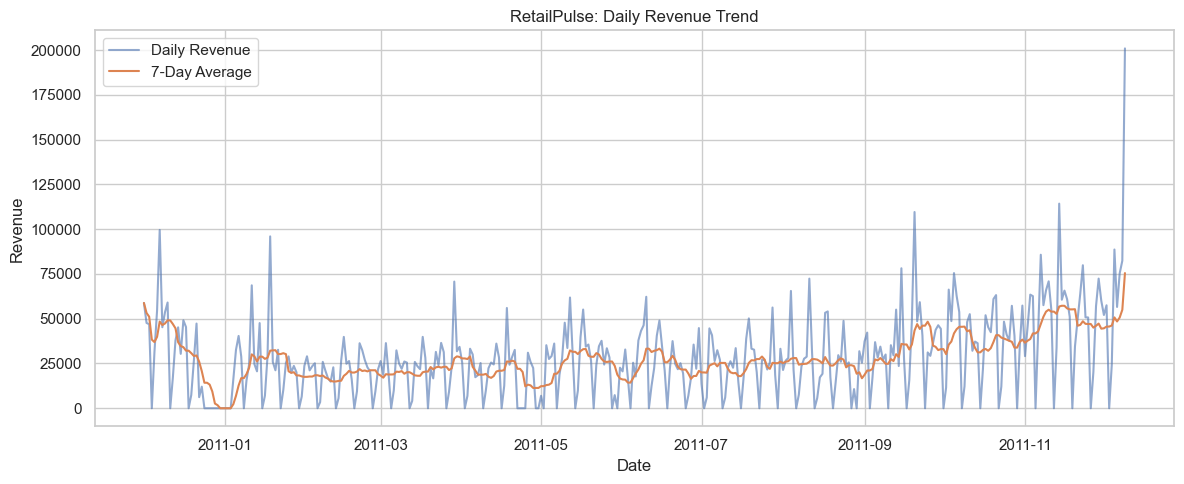

In [20]:
plt.figure(figsize=(12, 5))

plt.plot(
    daily_sales["Date"],
    daily_sales["DailyRevenue"],
    label="Daily Revenue",
    alpha=0.6
)

plt.plot(
    daily_sales["Date"],
    daily_sales["Revenue_7Day_Avg"],
    label="7-Day Average"
)

plt.title("RetailPulse: Daily Revenue Trend")
plt.xlabel("Date")
plt.ylabel("Revenue")
plt.legend()
plt.tight_layout()
plt.show()

In [22]:

import great_expectations as gx

# 1. Create the Great Expectations context
context = gx.get_context()

# 2. Create the data source
data_source = context.data_sources.add_pandas(
    name="retailpulse_day2_source"
)

# 3. Create the data asset
data_asset = data_source.add_dataframe_asset(
    name="retailpulse_sales"
)

# 4. Create the batch definition
batch_definition = data_asset.add_batch_definition_whole_dataframe(
    "retailpulse_sales_batch"
)

# 5. Prepare the sales data batch
batch = batch_definition.get_batch(
    batch_parameters={"dataframe": sales_df}
)

# 6. Create an expectation suite
suite = gx.ExpectationSuite(
    name="retailpulse_day2_suite"
)

# 7. Check InvoiceNo is not null
suite.add_expectation(
    gx.expectations.ExpectColumnValuesToNotBeNull(
        column="InvoiceNo"
    )
)

# 8. Check InvoiceDate is not null
suite.add_expectation(
    gx.expectations.ExpectColumnValuesToNotBeNull(
        column="InvoiceDate"
    )
)

# 9. Check Quantity is greater than zero
suite.add_expectation(
    gx.expectations.ExpectColumnValuesToBeBetween(
        column="Quantity",
        min_value=0,
        strict_min=True
    )
)

# 10. Check UnitPrice is greater than zero
suite.add_expectation(
    gx.expectations.ExpectColumnValuesToBeBetween(
        column="UnitPrice",
        min_value=0,
        strict_min=True
    )
)

# 11. Run validation
validation_result = batch.validate(suite)

# 12. Display the results
print(validation_result)


Calculating Metrics: 100%|████████████████| 27/27 [00:00<00:00, 202.74it/s]

{
  "success": true,
  "results": [
    {
      "success": true,
      "expectation_config": {
        "type": "expect_column_values_to_not_be_null",
        "kwargs": {
          "batch_id": "retailpulse_day2_source-retailpulse_sales",
          "column": "InvoiceNo"
        },
        "meta": {},
        "severity": "critical"
      },
      "result": {
        "element_count": 524878,
        "unexpected_count": 0,
        "unexpected_percent": 0.0,
        "partial_unexpected_list": [],
        "partial_unexpected_counts": [],
        "partial_unexpected_index_list": []
      },
      "meta": {},
      "exception_info": {
        "raised_exception": false,
        "exception_traceback": null,
        "exception_message": null
      }
    },
    {
      "success": true,
      "expectation_config": {
        "type": "expect_column_values_to_not_be_null",
        "kwargs": {
          "batch_id": "retailpulse_day2_source-retailpulse_sales",
          "column": "InvoiceDate"
        },

In [23]:
from pathlib import Path

output_dir = Path("../outputs")
output_dir.mkdir(parents=True, exist_ok=True)

df_clean.to_csv(
    output_dir / "day2_cleaned_transactions.csv",
    index=False
)

sales_df.to_csv(
    output_dir / "day2_sales_data.csv",
    index=False
)

rfm.to_csv(
    output_dir / "day2_rfm_features.csv",
    index=False
)

daily_sales.to_csv(
    output_dir / "day2_daily_sales_features.csv",
    index=False
)

print("Day 2 outputs saved successfully!")

Day 2 outputs saved successfully!


In [24]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import silhouette_score

sns.set_theme(style="whitegrid")

rfm = pd.read_csv("../outputs/day2_rfm_features.csv")

print("RFM data loaded successfully!")
print("Dataset shape:", rfm.shape)

display(rfm.head())

RFM data loaded successfully!
Dataset shape: (4338, 4)


,CustomerID,Recency,Frequency,Monetary
0,12346.0,326,1,77183.60
1,12347.0,3,7,4310.00
2,12348.0,76,4,1797.24
3,12349.0,19,1,1757.55
4,12350.0,311,1,334.40


In [25]:
print("Missing values:")
display(rfm.isnull().sum())

print("\nDuplicate customer IDs:", rfm["CustomerID"].duplicated().sum())

display(rfm[["Recency", "Frequency", "Monetary"]].describe())

Missing values:


CustomerID    0
Recency       0
Frequency     0
Monetary      0
dtype: int64


Duplicate customer IDs: 0


,Recency,Frequency,Monetary
count,4338.000000,4338.000000,4338.000000
mean,93.059474,4.272015,2048.688081
std,100.012264,7.697998,8985.230220
min,1.000000,1.000000,3.750000
25%,18.000000,1.000000,306.482500
50%,51.000000,2.000000,668.570000
75%,142.750000,5.000000,1660.597500
max,374.000000,209.000000,280206.020000


In [26]:
# Keep rows with valid RFM values
rfm_model = rfm.dropna(
    subset=["Recency", "Frequency", "Monetary"]
).copy()

# Remove impossible or unusable values for this analysis
rfm_model = rfm_model[
    (rfm_model["Recency"] >= 0) &
    (rfm_model["Frequency"] > 0) &
    (rfm_model["Monetary"] > 0)
].copy()

# Reduce skewness in the features
features = ["Recency", "Frequency", "Monetary"]

X_log = np.log1p(rfm_model[features])

# Standardize features so different scales do not dominate
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_log)

print("Customers ready for clustering:", len(rfm_model))
print("Prepared feature shape:", X_scaled.shape)

Customers ready for clustering: 4338
Prepared feature shape: (4338, 3)


In [27]:
scores = []

for k in range(2, 7):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X_scaled)
    score = silhouette_score(X_scaled, labels)

    scores.append({
        "Number_of_Clusters": k,
        "Silhouette_Score": score
    })

scores_df = pd.DataFrame(scores)
display(scores_df)

,Number_of_Clusters,Silhouette_Score
0,2,0.432509
1,3,0.336288
2,4,0.332902
3,5,0.318078
4,6,0.312873


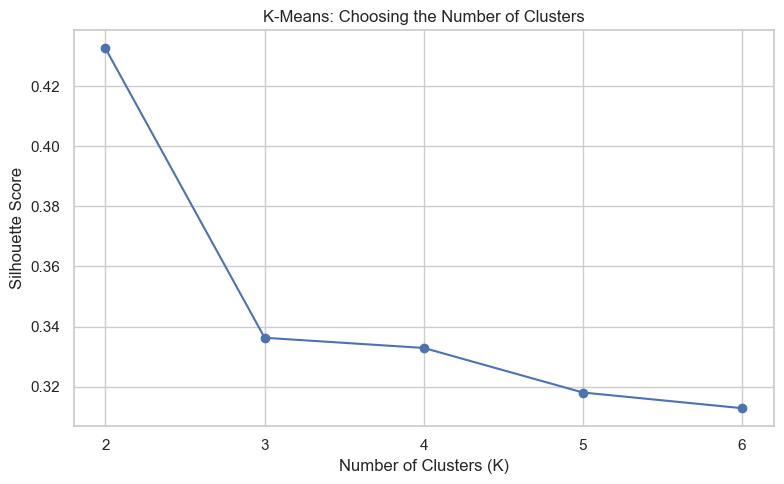

In [28]:
plt.figure(figsize=(8, 5))

plt.plot(
    scores_df["Number_of_Clusters"],
    scores_df["Silhouette_Score"],
    marker="o"
)

plt.title("K-Means: Choosing the Number of Clusters")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.xticks(range(2, 7))
plt.tight_layout()
plt.show()

K-Mean 

In [29]:
best_k = int(
    scores_df.loc[
        scores_df["Silhouette_Score"].idxmax(),
        "Number_of_Clusters"
    ]
)

kmeans = KMeans(
    n_clusters=best_k,
    random_state=42,
    n_init=10
)

rfm_model["KMeans_Cluster"] = kmeans.fit_predict(X_scaled)

print("Selected number of clusters:", best_k)
print("\nCustomers per cluster:")
display(
    rfm_model["KMeans_Cluster"]
    .value_counts()
    .sort_index()
)

Selected number of clusters: 2

Customers per cluster:


KMeans_Cluster
0    1668
1    2670
Name: count, dtype: int64

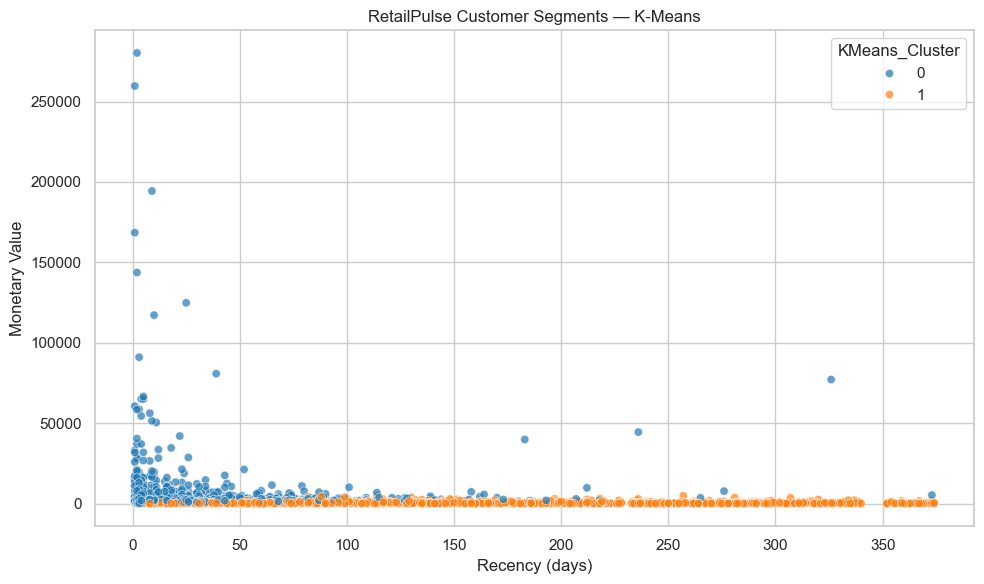

In [30]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=rfm_model,
    x="Recency",
    y="Monetary",
    hue="KMeans_Cluster",
    palette="tab10",
    alpha=0.7
)

plt.title("RetailPulse Customer Segments — K-Means")
plt.xlabel("Recency (days)")
plt.ylabel("Monetary Value")
plt.tight_layout()
plt.show()

In [31]:
cluster_summary = (
    rfm_model
    .groupby("KMeans_Cluster")
    .agg(
        Customer_Count=("CustomerID", "count"),
        Avg_Recency=("Recency", "mean"),
        Avg_Frequency=("Frequency", "mean"),
        Avg_Monetary=("Monetary", "mean")
    )
    .round(2)
)

display(cluster_summary)

,Customer_Count,Avg_Recency,Avg_Frequency,Avg_Monetary
KMeans_Cluster,,,,
0,1668,26.45,8.44,4535.74
1,2670,134.67,1.67,494.98


DBSCAN

In [32]:
dbscan = DBSCAN(
    eps=0.8,
    min_samples=5
)

dbscan_labels = dbscan.fit_predict(X_scaled)

rfm_model["DBSCAN_Cluster"] = dbscan_labels

print("DBSCAN cluster counts:")
display(
    rfm_model["DBSCAN_Cluster"]
    .value_counts()
    .sort_index()
)

print(
    "Noise points:",
    (rfm_model["DBSCAN_Cluster"] == -1).sum()
)

DBSCAN cluster counts:


DBSCAN_Cluster
-1      22
 0    4316
Name: count, dtype: int64

Noise points: 22


In [33]:
# K-Means silhouette score
kmeans_score = silhouette_score(
    X_scaled,
    rfm_model["KMeans_Cluster"]
)

print("K-Means silhouette score:", round(kmeans_score, 3))

# DBSCAN silhouette score, excluding noise
dbscan_mask = rfm_model["DBSCAN_Cluster"] != -1
dbscan_labels_filtered = rfm_model.loc[
    dbscan_mask, "DBSCAN_Cluster"
]
X_dbscan = X_scaled[dbscan_mask.to_numpy()]

n_dbscan_clusters = dbscan_labels_filtered.nunique()

if 2 <= n_dbscan_clusters < len(X_dbscan):
    dbscan_score = silhouette_score(
        X_dbscan,
        dbscan_labels_filtered
    )
    print("DBSCAN silhouette score:", round(dbscan_score, 3))
else:
    print(
        "DBSCAN silhouette score is not meaningful here: "
        "it did not produce at least two usable clusters."
    )

K-Means silhouette score: 0.433
DBSCAN silhouette score is not meaningful here: it did not produce at least two usable clusters.


In [34]:
from pathlib import Path

output_dir = Path("../outputs")
output_dir.mkdir(parents=True, exist_ok=True)

rfm_model.to_csv(
    output_dir / "day3_customer_segments.csv",
    index=False
)

cluster_summary.to_csv(
    output_dir / "day3_cluster_summary.csv"
)

scores_df.to_csv(
    output_dir / "day3_kmeans_evaluation.csv",
    index=False
)

print("Day 3 outputs saved successfully!")

Day 3 outputs saved successfully!


In [36]:
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller

In [37]:
sales_df = pd.read_csv(
    "../outputs/day2_sales_data.csv",
    parse_dates=["InvoiceDate"]
)

print("Sales data loaded:", sales_df.shape)
display(sales_df.head())

Sales data loaded: (524878, 9)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34


In [38]:
daily_sales = (
    sales_df
    .set_index("InvoiceDate")
    .resample("D")["Revenue"]
    .sum()
    .rename("DailyRevenue")
    .to_frame()
)

print("Daily time-series shape:", daily_sales.shape)
display(daily_sales.head())

Daily time-series shape: (374, 1)


,DailyRevenue
InvoiceDate,
2010-12-01,58776.79
2010-12-02,47629.42
2010-12-03,46898.63
2010-12-04,0.00
2010-12-05,31364.63


In [39]:
print("Start date:", daily_sales.index.min())
print("End date:", daily_sales.index.max())
print("Number of calendar days:", len(daily_sales))
print("Missing daily revenue values:", daily_sales["DailyRevenue"].isna().sum())
print("Duplicate dates:", daily_sales.index.duplicated().sum())

print("\nRevenue summary:")
display(daily_sales["DailyRevenue"].describe())

Start date: 2010-12-01 00:00:00
End date: 2011-12-09 00:00:00
Number of calendar days: 374
Missing daily revenue values: 0
Duplicate dates: 0

Revenue summary:


count       374.000000
mean      28454.841722
std       23376.423816
min           0.000000
25%       12093.075000
50%       25919.560000
75%       39849.810000
max      200900.980000
Name: DailyRevenue, dtype: float64

In [40]:
daily_sales["DayOfWeek"] = daily_sales.index.dayofweek
daily_sales["Month"] = daily_sales.index.month
daily_sales["Year"] = daily_sales.index.year

daily_sales["DayType"] = np.where(
    daily_sales["DayOfWeek"] >= 5,
    "Weekend",
    "Weekday"
)

display(daily_sales.head(10))

,DailyRevenue,DayOfWeek,Month,Year,DayType
InvoiceDate,,,,,
2010-12-01,58776.79,2,12,2010,Weekday
2010-12-02,47629.42,3,12,2010,Weekday
2010-12-03,46898.63,4,12,2010,Weekday
2010-12-04,0.00,5,12,2010,Weekend
2010-12-05,31364.63,6,12,2010,Weekend
2010-12-06,54624.15,0,12,2010,Weekday
2010-12-07,99553.85,1,12,2010,Weekday
2010-12-08,45235.36,2,12,2010,Weekday
2010-12-09,53548.19,3,12,2010,Weekday


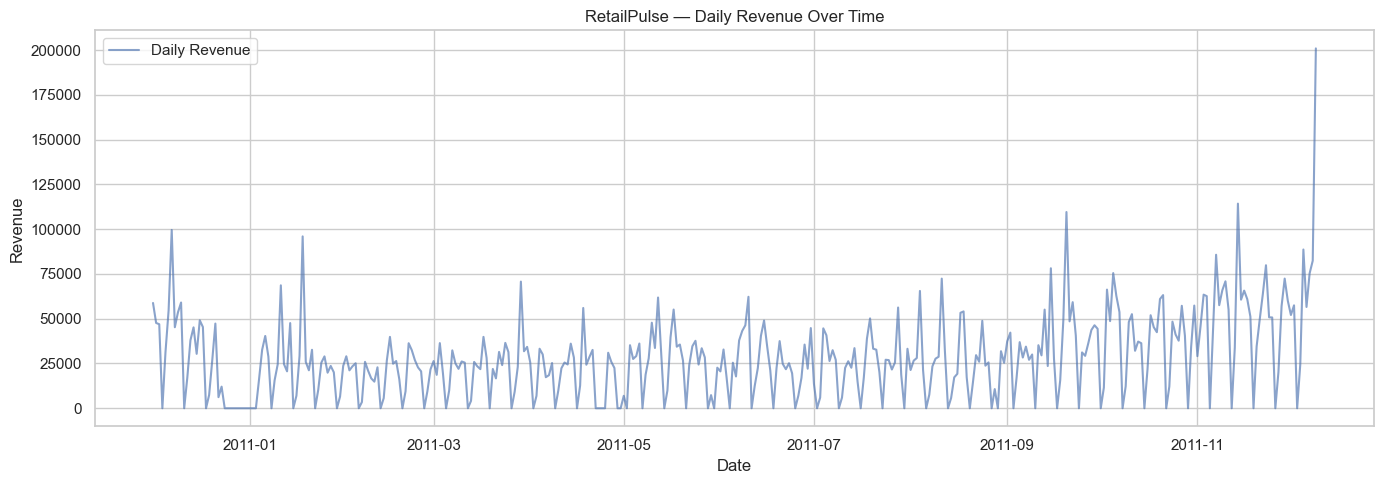

In [41]:
plt.figure(figsize=(14, 5))

plt.plot(
    daily_sales.index,
    daily_sales["DailyRevenue"],
    label="Daily Revenue",
    alpha=0.65
)

plt.title("RetailPulse — Daily Revenue Over Time")
plt.xlabel("Date")
plt.ylabel("Revenue")
plt.legend()
plt.tight_layout()
plt.show()

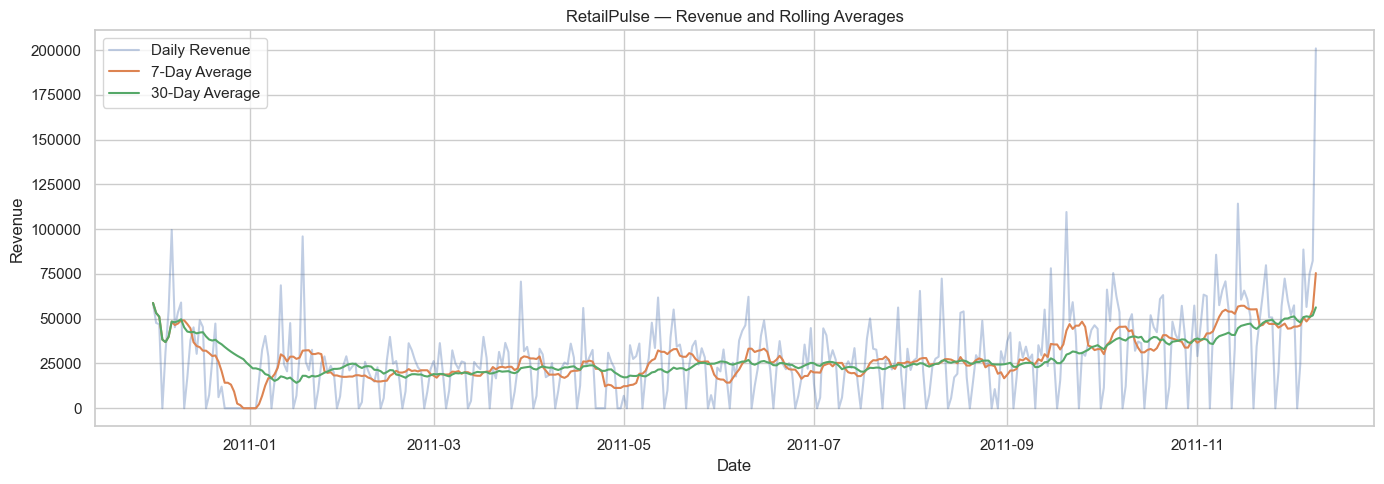

In [42]:
daily_sales["Revenue_7Day_Avg"] = (
    daily_sales["DailyRevenue"]
    .rolling(window=7, min_periods=1)
    .mean()
)

daily_sales["Revenue_30Day_Avg"] = (
    daily_sales["DailyRevenue"]
    .rolling(window=30, min_periods=1)
    .mean()
)

plt.figure(figsize=(14, 5))

plt.plot(
    daily_sales.index,
    daily_sales["DailyRevenue"],
    label="Daily Revenue",
    alpha=0.35
)

plt.plot(
    daily_sales.index,
    daily_sales["Revenue_7Day_Avg"],
    label="7-Day Average"
)

plt.plot(
    daily_sales.index,
    daily_sales["Revenue_30Day_Avg"],
    label="30-Day Average"
)

plt.title("RetailPulse — Revenue and Rolling Averages")
plt.xlabel("Date")
plt.ylabel("Revenue")
plt.legend()
plt.tight_layout()
plt.show()

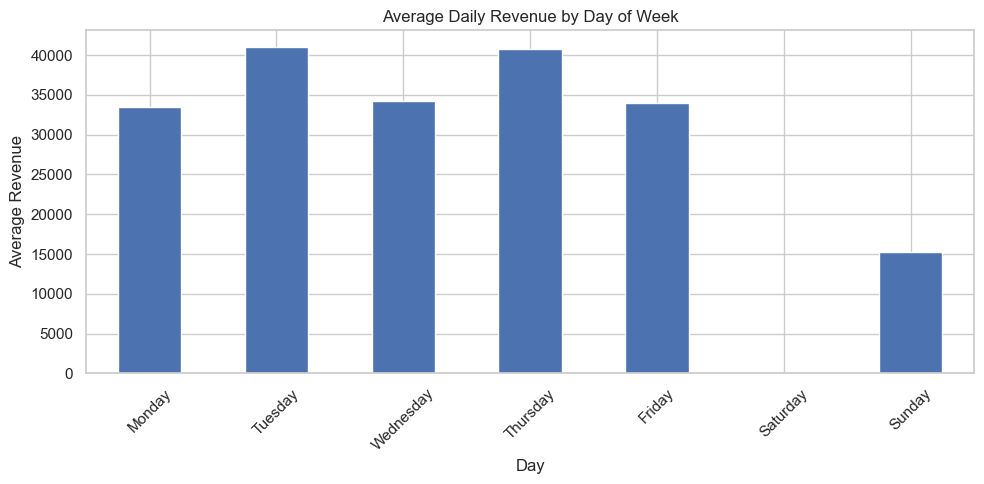

In [43]:
weekday_revenue = daily_sales.groupby(
    "DayOfWeek"
)["DailyRevenue"].mean()

weekday_names = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

weekday_revenue.index = [
    weekday_names[i] for i in weekday_revenue.index
]

weekday_revenue = weekday_revenue.reindex(weekday_names)

weekday_revenue.plot(kind="bar", figsize=(10, 5))

plt.title("Average Daily Revenue by Day of Week")
plt.xlabel("Day")
plt.ylabel("Average Revenue")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

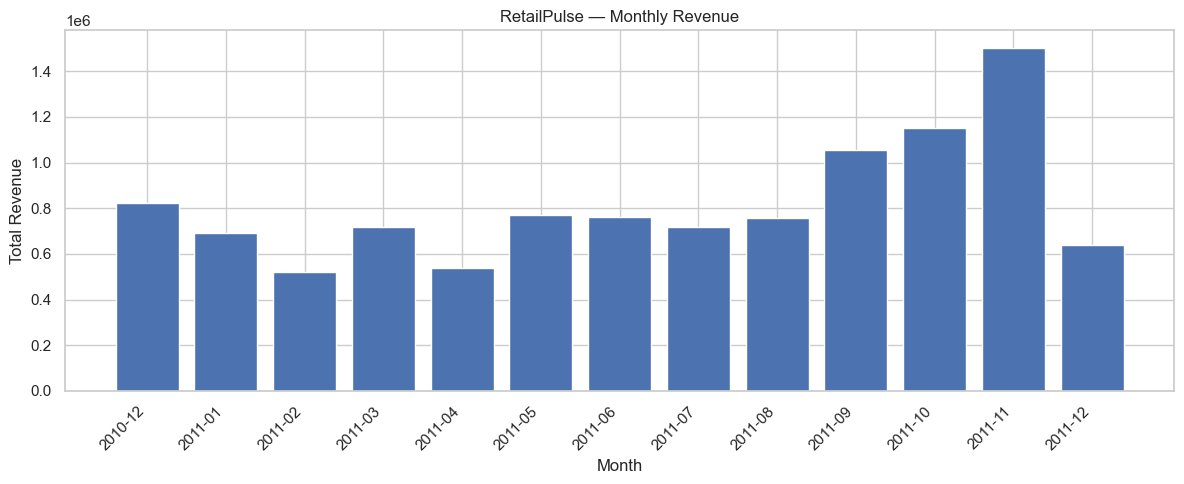

,MonthlyRevenue
InvoiceDate,
2010-12-01,821452.730
2011-01-01,689811.610
2011-02-01,522545.560
2011-03-01,716215.260
2011-04-01,536968.491
2011-05-01,769296.610
2011-06-01,760547.010
2011-07-01,718076.121
2011-08-01,757841.380


In [45]:

# Calculate total revenue for each month
monthly_revenue = daily_sales["DailyRevenue"].resample("MS").sum()

# Plot monthly revenue using Matplotlib directly
plt.figure(figsize=(12, 5))

plt.bar(
    monthly_revenue.index.strftime("%Y-%m"),
    monthly_revenue.values
)

plt.title("RetailPulse — Monthly Revenue")
plt.xlabel("Month")
plt.ylabel("Total Revenue")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

# Display the monthly revenue values
display(monthly_revenue.to_frame("MonthlyRevenue"))


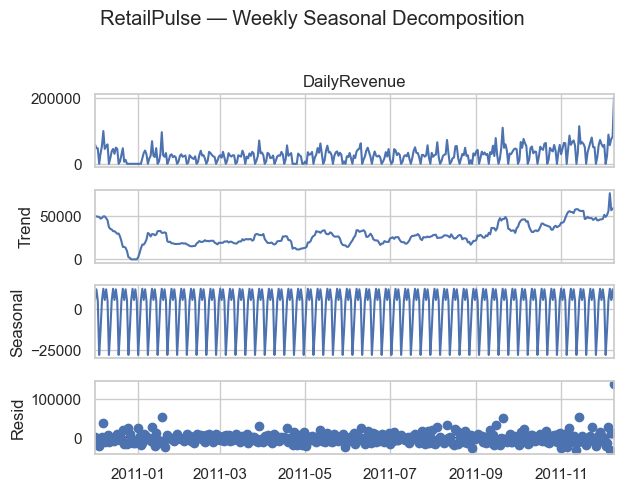

In [46]:

from statsmodels.tsa.seasonal import seasonal_decompose
import matplotlib.pyplot as plt

# Check that enough daily observations are available
if len(daily_sales) >= 14:
    decomposition = seasonal_decompose(
        daily_sales["DailyRevenue"],
        model="additive",
        period=7,
        extrapolate_trend="freq"
    )

    decomposition.plot()
    plt.suptitle(
        "RetailPulse — Weekly Seasonal Decomposition",
        y=1.02
    )
    plt.tight_layout()
    plt.show()
else:
    print("Not enough daily observations for decomposition.")


In [47]:

from statsmodels.tsa.stattools import adfuller

revenue_series = daily_sales["DailyRevenue"].dropna()

adf_result = adfuller(revenue_series)

print("ADF Statistic:", round(adf_result[0], 4))
print("P-value:", round(adf_result[1], 6))
print("Lags Used:", adf_result[2])
print("Observations Used:", adf_result[3])

if adf_result[1] < 0.05:
    print("Conclusion: Reject the unit-root null hypothesis.")
    print("The series shows evidence of stationarity.")
else:
    print("Conclusion: Fail to reject the unit-root null hypothesis.")
    print("The series may be non-stationary.")


ADF Statistic: -0.6417
P-value: 0.861281
Lags Used: 13
Observations Used: 360
Conclusion: Fail to reject the unit-root null hypothesis.
The series may be non-stationary.


In [48]:

split_index = int(len(daily_sales) * 0.8)

train = daily_sales.iloc[:split_index].copy()
test = daily_sales.iloc[split_index:].copy()

print("Training rows:", len(train))
print("Testing rows:", len(test))

print("\nTraining period:")
print(train.index.min(), "to", train.index.max())

print("\nTesting period:")
print(test.index.min(), "to", test.index.max())


Training rows: 299
Testing rows: 75

Training period:
2010-12-01 00:00:00 to 2011-09-25 00:00:00

Testing period:
2011-09-26 00:00:00 to 2011-12-09 00:00:00


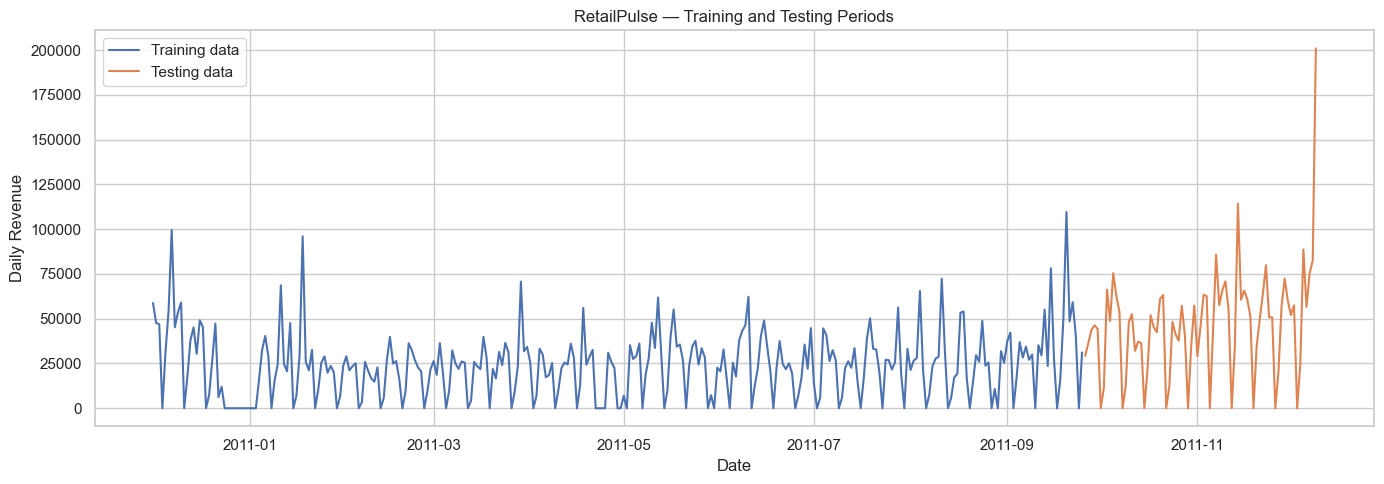

In [49]:

plt.figure(figsize=(14, 5))

plt.plot(
    train.index,
    train["DailyRevenue"],
    label="Training data"
)

plt.plot(
    test.index,
    test["DailyRevenue"],
    label="Testing data"
)

plt.title("RetailPulse — Training and Testing Periods")
plt.xlabel("Date")
plt.ylabel("Daily Revenue")
plt.legend()
plt.tight_layout()
plt.show()


In [50]:

from pathlib import Path

output_dir = Path("../outputs")
output_dir.mkdir(parents=True, exist_ok=True)

daily_sales.to_csv(
    output_dir / "day4_daily_time_series.csv",
    index_label="Date"
)

train.to_csv(
    output_dir / "day4_train.csv",
    index_label="Date"
)

test.to_csv(
    output_dir / "day4_test.csv",
    index_label="Date"
)

monthly_revenue.to_csv(
    output_dir / "day4_monthly_revenue.csv",
    index_label="Date"
)

print("Day 4 outputs saved successfully!")

print("\nFiles saved:")
for filename in [
    "day4_daily_time_series.csv",
    "day4_train.csv",
    "day4_test.csv",
    "day4_monthly_revenue.csv"
]:
    print(output_dir / filename)


Day 4 outputs saved successfully!

Files saved:
..\outputs\day4_daily_time_series.csv
..\outputs\day4_train.csv
..\outputs\day4_test.csv
..\outputs\day4_monthly_revenue.csv


DAY _ 5
->set up Prophet 
->Train and forecast
->Evaluate and save 

In [51]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from prophet import Prophet
from sklearn.metrics import mean_absolute_error, mean_squared_error

print("Libraries imported successfully!")

Libraries imported successfully!


In [52]:
train_df = pd.read_csv(
    "../outputs/day4_train.csv",
    parse_dates=["Date"]
)

test_df = pd.read_csv(
    "../outputs/day4_test.csv",
    parse_dates=["Date"]
)

print("Training data shape:", train_df.shape)
print("Testing data shape:", test_df.shape)

display(train_df.head())
display(test_df.head())

Training data shape: (299, 8)
Testing data shape: (75, 8)


,Date,DailyRevenue,DayOfWeek,Month,Year,DayType,Revenue_7Day_Avg,Revenue_30Day_Avg
0,2010-12-01,58776.79,2,12,2010,Weekday,58776.790000,58776.790000
1,2010-12-02,47629.42,3,12,2010,Weekday,53203.105000,53203.105000
2,2010-12-03,46898.63,4,12,2010,Weekday,51101.613333,51101.613333
3,2010-12-04,0.00,5,12,2010,Weekend,38326.210000,38326.210000
4,2010-12-05,31364.63,6,12,2010,Weekend,36933.894000,36933.894000


,Date,DailyRevenue,DayOfWeek,Month,Year,DayType,Revenue_7Day_Avg,Revenue_30Day_Avg
0,2011-09-26,29270.841,0,9,2011,Weekday,45473.436000,31789.411400
1,2011-09-27,36260.910,1,9,2011,Weekday,35003.008857,32641.889733
2,2011-09-28,43693.080,2,9,2011,Weekday,34312.060286,34098.325733
3,2011-09-29,46343.350,3,9,2011,Weekday,32472.480286,34581.845067
4,2011-09-30,44347.060,4,9,2011,Weekday,33011.431714,35214.506400


In [53]:
train_prophet = train_df[["Date", "DailyRevenue"]].rename(
    columns={
        "Date": "ds",
        "DailyRevenue": "y"
    }
)

test_prophet = test_df[["Date", "DailyRevenue"]].rename(
    columns={
        "Date": "ds",
        "DailyRevenue": "y"
    }
)

# Remove rows with missing dates or target values
train_prophet = train_prophet.dropna().sort_values("ds")
test_prophet = test_prophet.dropna().sort_values("ds")

print("Training period:", train_prophet["ds"].min(), "to", train_prophet["ds"].max())
print("Testing period:", test_prophet["ds"].min(), "to", test_prophet["ds"].max())

display(train_prophet.head())

Training period: 2010-12-01 00:00:00 to 2011-09-25 00:00:00
Testing period: 2011-09-26 00:00:00 to 2011-12-09 00:00:00


,ds,y
0,2010-12-01,58776.79
1,2010-12-02,47629.42
2,2010-12-03,46898.63
3,2010-12-04,0.00
4,2010-12-05,31364.63


In [54]:
model = Prophet(
    weekly_seasonality=True,
    yearly_seasonality=False,
    daily_seasonality=False,
    interval_width=0.95
)

model.fit(train_prophet)

print("Prophet model trained successfully!")

18:53:12 - cmdstanpy - INFO - Chain [1] start processing
18:53:12 - cmdstanpy - INFO - Chain [1] done processing


Prophet model trained successfully!


In [55]:
future = model.make_future_dataframe(
    periods=len(test_prophet),
    freq="D"
)

forecast = model.predict(future)

# Keep predictions only for test dates
test_forecast = test_prophet[["ds", "y"]].merge(
    forecast[["ds", "yhat", "yhat_lower", "yhat_upper"]],
    on="ds",
    how="left"
)

print("Forecast generated successfully!")
display(test_forecast.head(10))

Forecast generated successfully!


,ds,y,yhat,yhat_lower,yhat_upper
0,2011-09-26,29270.841,30569.762101,5223.380108,58089.124103
1,2011-09-27,36260.910,43261.700426,17067.085960,69223.054133
2,2011-09-28,43693.080,33338.127546,7337.969838,57974.121406
3,2011-09-29,46343.350,41053.020079,14111.275200,66841.845271
4,2011-09-30,44347.060,31039.520706,6195.196435,57279.553619
5,2011-10-01,0.000,5041.015168,-21095.428874,30849.958213
6,2011-10-02,11531.560,18041.905115,-10656.512713,41546.941520
7,2011-10-03,66243.940,30861.260497,5720.137980,57140.114482
8,2011-10-04,48652.540,43553.198822,17407.213205,70397.862925
9,2011-10-05,75460.770,33629.625942,5370.595698,61572.459167


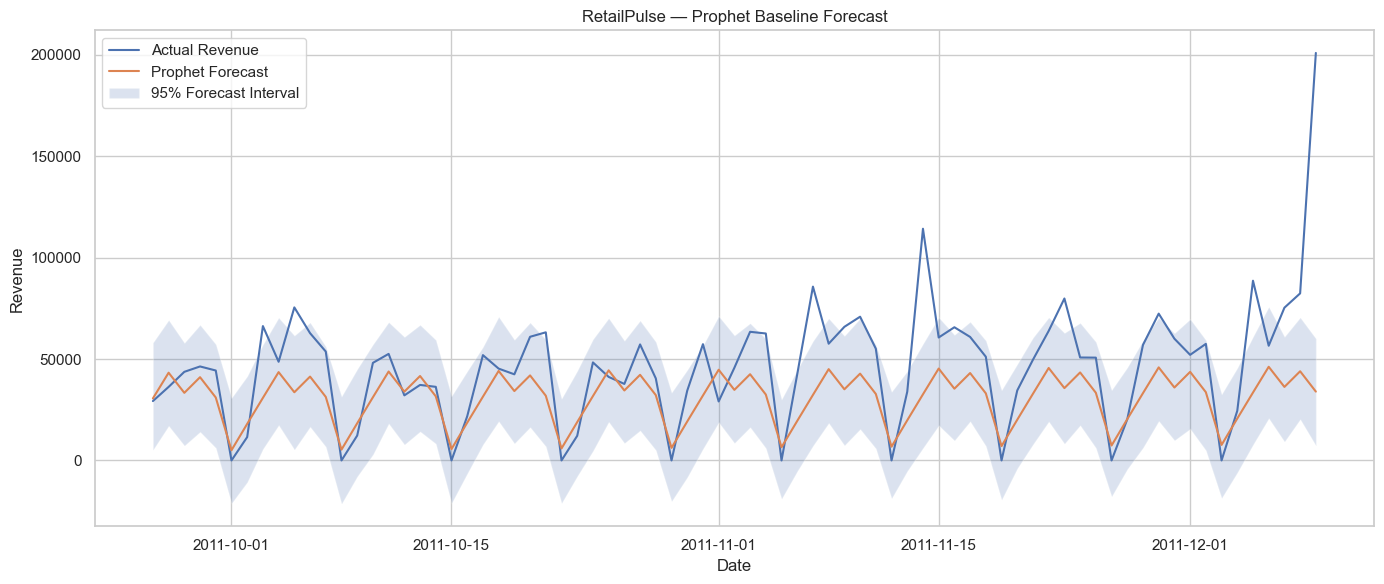

In [56]:
plt.figure(figsize=(14, 6))

plt.plot(
    test_forecast["ds"],
    test_forecast["y"],
    label="Actual Revenue"
)

plt.plot(
    test_forecast["ds"],
    test_forecast["yhat"],
    label="Prophet Forecast"
)

plt.fill_between(
    test_forecast["ds"],
    test_forecast["yhat_lower"],
    test_forecast["yhat_upper"],
    alpha=0.2,
    label="95% Forecast Interval"
)

plt.title("RetailPulse — Prophet Baseline Forecast")
plt.xlabel("Date")
plt.ylabel("Revenue")
plt.legend()
plt.tight_layout()
plt.show()

In [57]:
actual = test_forecast["y"].to_numpy()
predicted = test_forecast["yhat"].to_numpy()

mae = mean_absolute_error(actual, predicted)

rmse = np.sqrt(
    mean_squared_error(actual, predicted)
)

total_actual = np.abs(actual).sum()

wape = (
    np.abs(actual - predicted).sum() / total_actual * 100
    if total_actual != 0
    else np.nan
)

print("Prophet Baseline Evaluation")
print("---------------------------")
print(f"MAE:  {mae:.2f}")
print(f"RMSE: {rmse:.2f}")
print(f"WAPE: {wape:.2f}%")

Prophet Baseline Evaluation
---------------------------
MAE:  18885.85
RMSE: 29296.78
WAPE: 40.55%


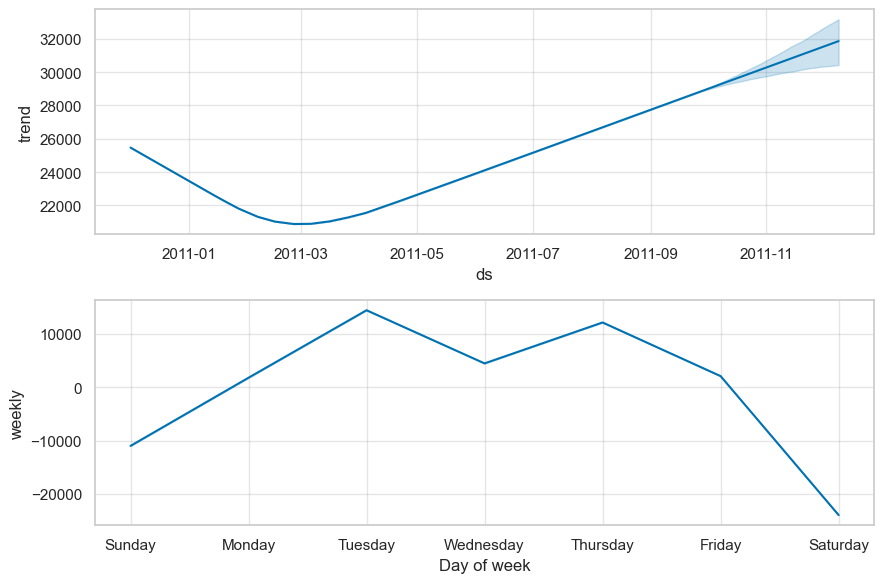

In [58]:
model.plot_components(forecast)
plt.tight_layout()
plt.show()

In [59]:
from pathlib import Path
from prophet.serialize import model_to_json

output_dir = Path("../outputs")
output_dir.mkdir(parents=True, exist_ok=True)

# Save test-period forecasts
test_forecast.to_csv(
    output_dir / "day5_prophet_test_forecast.csv",
    index=False
)

# Save evaluation metrics
metrics_df = pd.DataFrame([{
    "Model": "Prophet Baseline",
    "MAE": mae,
    "RMSE": rmse,
    "WAPE_Percent": wape
}])

metrics_df.to_csv(
    output_dir / "day5_prophet_metrics.csv",
    index=False
)

# Save the trained model
with open(
    output_dir / "day5_prophet_model.json",
    "w",
    encoding="utf-8"
) as file:
    file.write(model_to_json(model))

print("Day 5 outputs saved successfully!")
display(metrics_df)

Day 5 outputs saved successfully!


,Model,MAE,RMSE,WAPE_Percent
0,Prophet Baseline,18885.854718,29296.783463,40.552693


DAY _ 6 
->data 
-> Train LSTM 
-> Forecast and evaluate

In [60]:
import torch
import torch.nn as nn

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

print("PyTorch version:", torch.__version__)
print("Libraries imported successfully!")

PyTorch version: 2.11.0+cpu
Libraries imported successfully!


In [61]:
train_df = pd.read_csv(
    "../outputs/day4_train.csv",
    parse_dates=["Date"]
)

test_df = pd.read_csv(
    "../outputs/day4_test.csv",
    parse_dates=["Date"]
)

train_df = train_df.sort_values("Date").reset_index(drop=True)
test_df = test_df.sort_values("Date").reset_index(drop=True)

print("Training rows:", len(train_df))
print("Testing rows:", len(test_df))

display(train_df.head())
display(test_df.head())

Training rows: 299
Testing rows: 75


,Date,DailyRevenue,DayOfWeek,Month,Year,DayType,Revenue_7Day_Avg,Revenue_30Day_Avg
0,2010-12-01,58776.79,2,12,2010,Weekday,58776.790000,58776.790000
1,2010-12-02,47629.42,3,12,2010,Weekday,53203.105000,53203.105000
2,2010-12-03,46898.63,4,12,2010,Weekday,51101.613333,51101.613333
3,2010-12-04,0.00,5,12,2010,Weekend,38326.210000,38326.210000
4,2010-12-05,31364.63,6,12,2010,Weekend,36933.894000,36933.894000


,Date,DailyRevenue,DayOfWeek,Month,Year,DayType,Revenue_7Day_Avg,Revenue_30Day_Avg
0,2011-09-26,29270.841,0,9,2011,Weekday,45473.436000,31789.411400
1,2011-09-27,36260.910,1,9,2011,Weekday,35003.008857,32641.889733
2,2011-09-28,43693.080,2,9,2011,Weekday,34312.060286,34098.325733
3,2011-09-29,46343.350,3,9,2011,Weekday,32472.480286,34581.845067
4,2011-09-30,44347.060,4,9,2011,Weekday,33011.431714,35214.506400


In [62]:
print("Missing training revenue:", train_df["DailyRevenue"].isna().sum())
print("Missing testing revenue:", test_df["DailyRevenue"].isna().sum())

print("Training date range:", train_df["Date"].min(), "to", train_df["Date"].max())
print("Testing date range:", test_df["Date"].min(), "to", test_df["Date"].max())

Missing training revenue: 0
Missing testing revenue: 0
Training date range: 2010-12-01 00:00:00 to 2011-09-25 00:00:00
Testing date range: 2011-09-26 00:00:00 to 2011-12-09 00:00:00


In [63]:
LOOKBACK = 14

train_values = train_df["DailyRevenue"].to_numpy(dtype=np.float32).reshape(-1, 1)
test_values = test_df["DailyRevenue"].to_numpy(dtype=np.float32).reshape(-1, 1)

if len(train_values) <= LOOKBACK or len(test_values) == 0:
    raise ValueError("Not enough training or testing data for a 14-day lookback.")

scaler = MinMaxScaler()

train_scaled = scaler.fit_transform(train_values)
test_scaled = scaler.transform(test_values)

def create_sequences(values, lookback=14):
    X, y = [], []

    for i in range(lookback, len(values)):
        X.append(values[i - lookback:i, 0])
        y.append(values[i, 0])

    return np.array(X), np.array(y)

X_train, y_train = create_sequences(train_scaled, LOOKBACK)

print("Training input shape:", X_train.shape)
print("Training target shape:", y_train.shape)

Training input shape: (285, 14)
Training target shape: (285,)


In [64]:
X_train_tensor = torch.tensor(
    X_train, dtype=torch.float32
).unsqueeze(-1)

y_train_tensor = torch.tensor(
    y_train, dtype=torch.float32
).unsqueeze(-1)

print("LSTM input shape:", X_train_tensor.shape)
print("LSTM target shape:", y_train_tensor.shape)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Training device:", device)

LSTM input shape: torch.Size([285, 14, 1])
LSTM target shape: torch.Size([285, 1])
Training device: cpu


In [65]:
class RetailLSTM(nn.Module):
    def __init__(self, hidden_size=32):
        super().__init__()

        self.lstm = nn.LSTM(
            input_size=1,
            hidden_size=hidden_size,
            num_layers=1,
            batch_first=True
        )

        self.fc = nn.Linear(hidden_size, 1)

    def forward(self, x):
        output, _ = self.lstm(x)
        last_output = output[:, -1, :]
        return self.fc(last_output)


torch.manual_seed(42)

model = RetailLSTM(hidden_size=32).to(device)

criterion = nn.MSELoss()
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

X_train_tensor = X_train_tensor.to(device)
y_train_tensor = y_train_tensor.to(device)

EPOCHS = 50

loss_history = []

for epoch in range(EPOCHS):
    model.train()

    optimizer.zero_grad()

    predictions = model(X_train_tensor)
    loss = criterion(predictions, y_train_tensor)

    loss.backward()
    optimizer.step()

    loss_history.append(loss.item())

    if (epoch + 1) % 10 == 0:
        print(
            f"Epoch [{epoch + 1}/{EPOCHS}], "
            f"Loss: {loss.item():.6f}"
        )

print("LSTM training completed!")

Epoch [10/50], Loss: 0.054032
Epoch [20/50], Loss: 0.032708
Epoch [30/50], Loss: 0.025901
Epoch [40/50], Loss: 0.026827
Epoch [50/50], Loss: 0.025861
LSTM training completed!


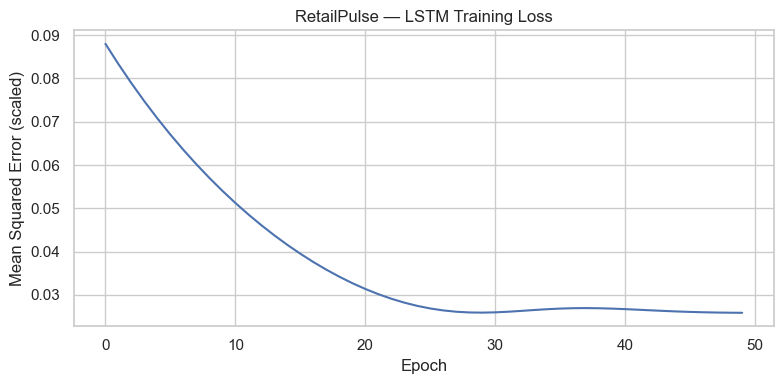

In [66]:
plt.figure(figsize=(8, 4))

plt.plot(loss_history)

plt.title("RetailPulse — LSTM Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error (scaled)")
plt.tight_layout()
plt.show()

In [67]:
model.eval()

history = list(train_scaled.flatten())
predictions_scaled = []

with torch.no_grad():
    for actual_scaled in test_scaled.flatten():
        # Use the previous 14 days to predict the next day
        sequence = np.array(
            history[-LOOKBACK:],
            dtype=np.float32
        ).reshape(1, LOOKBACK, 1)

        input_tensor = torch.tensor(
            sequence,
            dtype=torch.float32
        ).to(device)

        prediction = model(input_tensor)

        predictions_scaled.append(
            prediction.cpu().numpy()[0, 0]
        )

        # The next day's actual value becomes available
        # for the following day's forecast
        history.append(float(actual_scaled))

predictions = scaler.inverse_transform(
    np.array(predictions_scaled).reshape(-1, 1)
).flatten()

lstm_forecast = pd.DataFrame({
    "Date": test_df["Date"],
    "ActualRevenue": test_values.flatten(),
    "LSTM_Forecast": predictions
})

display(lstm_forecast.head(10))

,Date,ActualRevenue,LSTM_Forecast
0,2011-09-26,29270.841797,23801.363281
1,2011-09-27,36260.910156,23678.039062
2,2011-09-28,43693.078125,23800.277344
3,2011-09-29,46343.351562,24117.093750
4,2011-09-30,44347.058594,24435.250000
5,2011-10-01,0.000000,24609.787109
6,2011-10-02,11531.559570,23544.976562
7,2011-10-03,66243.937500,22939.087891
8,2011-10-04,48652.539062,23990.375000
9,2011-10-05,75460.773438,24504.128906


In [68]:
actual = lstm_forecast["ActualRevenue"].to_numpy()
predicted = lstm_forecast["LSTM_Forecast"].to_numpy()

mae = mean_absolute_error(actual, predicted)

rmse = np.sqrt(
    mean_squared_error(actual, predicted)
)

total_actual = np.abs(actual).sum()

wape = (
    np.abs(actual - predicted).sum() / total_actual * 100
    if total_actual != 0
    else np.nan
)

print("LSTM Forecast Evaluation")
print("------------------------")
print(f"MAE:  {mae:.2f}")
print(f"RMSE: {rmse:.2f}")
print(f"WAPE: {wape:.2f}%")

LSTM Forecast Evaluation
------------------------
MAE:  29734.50
RMSE: 37482.44
WAPE: 63.85%


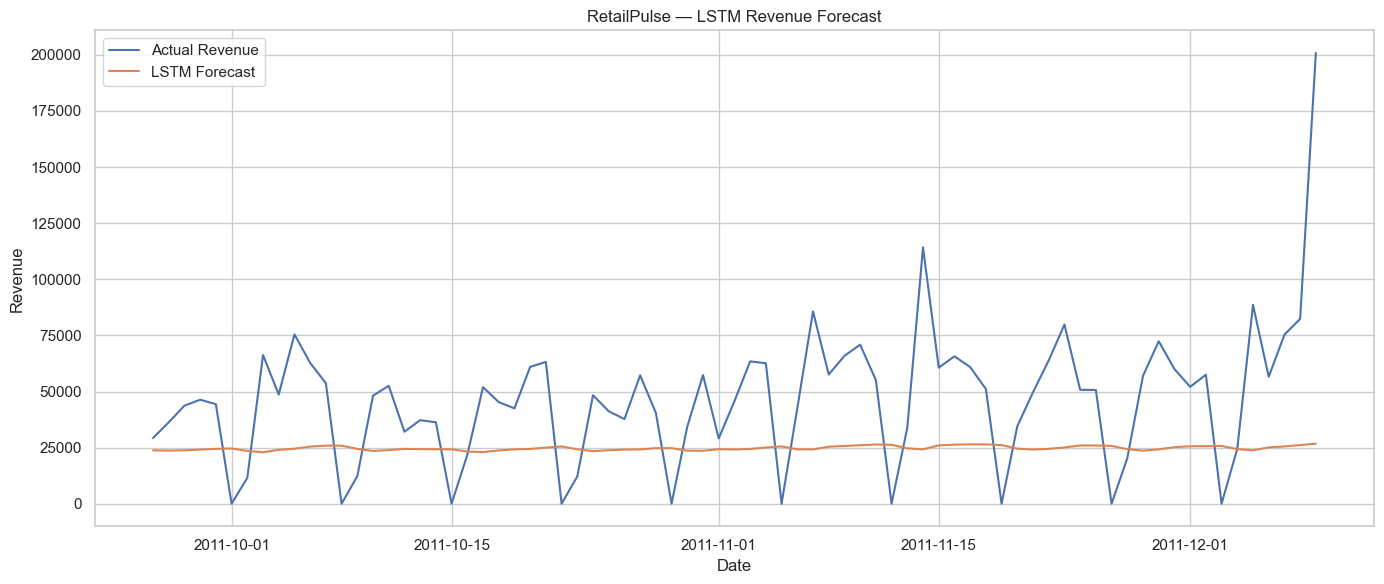

In [69]:
plt.figure(figsize=(14, 6))

plt.plot(
    lstm_forecast["Date"],
    lstm_forecast["ActualRevenue"],
    label="Actual Revenue"
)

plt.plot(
    lstm_forecast["Date"],
    lstm_forecast["LSTM_Forecast"],
    label="LSTM Forecast"
)

plt.title("RetailPulse — LSTM Revenue Forecast")
plt.xlabel("Date")
plt.ylabel("Revenue")
plt.legend()
plt.tight_layout()
plt.show()

In [70]:
prophet_metrics = pd.read_csv(
    "../outputs/day5_prophet_metrics.csv"
)

lstm_metrics = pd.DataFrame([{
    "Model": "LSTM",
    "MAE": mae,
    "RMSE": rmse,
    "WAPE_Percent": wape
}])

comparison = pd.concat(
    [prophet_metrics, lstm_metrics],
    ignore_index=True
)

display(comparison)

,Model,MAE,RMSE,WAPE_Percent
0,Prophet Baseline,18885.854718,29296.783463,40.552693
1,LSTM,29734.503906,37482.444317,63.847481


In [71]:
from pathlib import Path

output_dir = Path("../outputs")
output_dir.mkdir(parents=True, exist_ok=True)

# Save forecasts
lstm_forecast.to_csv(
    output_dir / "day6_lstm_forecast.csv",
    index=False
)

# Save model comparison
comparison.to_csv(
    output_dir / "day6_model_comparison.csv",
    index=False
)

# Save the trained PyTorch model
torch.save(
    model.state_dict(),
    output_dir / "day6_lstm_model.pth"
)

# Save the fitted scaler
import joblib

joblib.dump(
    scaler,
    output_dir / "day6_lstm_scaler.pkl"
)

print("Day 6 outputs saved successfully!")

Day 6 outputs saved successfully!


# RetailPulse — Day 7 Checkpoint Review

Objectives:
- Review initial exploratory data analysis.
- Validate cleaned transaction and customer data.
- Review customer segmentation and time-series preparation.
- Compare Prophet and LSTM forecasting results.
- Record project issues and next steps.

In [72]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

OUTPUT_DIR = Path("../outputs")

required_files = [
    "day1_missing_values.csv",
    "day1_correlation_matrix.csv",
    "day2_cleaned_transactions.csv",
    "day2_sales_data.csv",
    "day2_rfm_features.csv",
    "day2_daily_sales_features.csv",
    "day3_customer_segments.csv",
    "day3_cluster_summary.csv",
    "day4_daily_time_series.csv",
    "day4_train.csv",
    "day4_test.csv",
    "day5_prophet_test_forecast.csv",
    "day5_prophet_metrics.csv",
    "day6_lstm_forecast.csv",
    "day6_model_comparison.csv",
    "day6_lstm_model.pth",
    "day6_lstm_scaler.pkl",
]

for filename in required_files:
    path = OUTPUT_DIR / filename
    status = "FOUND" if path.exists() else "MISSING"
    print(f"{status}: {filename}")

FOUND: day1_missing_values.csv
FOUND: day1_correlation_matrix.csv
FOUND: day2_cleaned_transactions.csv
FOUND: day2_sales_data.csv
FOUND: day2_rfm_features.csv
FOUND: day2_daily_sales_features.csv
FOUND: day3_customer_segments.csv
FOUND: day3_cluster_summary.csv
FOUND: day4_daily_time_series.csv
FOUND: day4_train.csv
FOUND: day4_test.csv
FOUND: day5_prophet_test_forecast.csv
FOUND: day5_prophet_metrics.csv
FOUND: day6_lstm_forecast.csv
FOUND: day6_model_comparison.csv
FOUND: day6_lstm_model.pth
FOUND: day6_lstm_scaler.pkl


In [73]:
missing_path = OUTPUT_DIR / "day1_missing_values.csv"
corr_path = OUTPUT_DIR / "day1_correlation_matrix.csv"

if missing_path.exists():
    print("Missing-value summary:")
    display(pd.read_csv(missing_path).head(15))

if corr_path.exists():
    print("Correlation matrix:")
    display(pd.read_csv(corr_path).head(10))

Missing-value summary:


,Unnamed: 0,Missing_Count,Missing_Percentage
0,InvoiceNo,0,0.00
1,StockCode,0,0.00
2,Description,1454,0.27
3,Quantity,0,0.00
4,InvoiceDate,0,0.00
5,UnitPrice,0,0.00
6,CustomerID,135080,24.93
7,Country,0,0.00


Correlation matrix:


,Unnamed: 0,Quantity,UnitPrice,Revenue
0,Quantity,1.000000,-0.001235,0.886681
1,UnitPrice,-0.001235,1.000000,-0.162029
2,Revenue,0.886681,-0.162029,1.000000


In [74]:
cleaned = pd.read_csv(
    OUTPUT_DIR / "day2_cleaned_transactions.csv"
)
sales = pd.read_csv(
    OUTPUT_DIR / "day2_sales_data.csv"
)
rfm = pd.read_csv(
    OUTPUT_DIR / "day2_rfm_features.csv"
)
daily = pd.read_csv(
    OUTPUT_DIR / "day2_daily_sales_features.csv"
)

print("Cleaned transactions:", cleaned.shape)
print("Sales data:", sales.shape)
print("RFM customer data:", rfm.shape)
print("Daily sales data:", daily.shape)

print("\nCleaned data sample:")
display(cleaned.head())

print("\nRFM sample:")
display(rfm.head())

print("\nDaily sales sample:")
display(daily.head())

Cleaned transactions: (536641, 9)
Sales data: (524878, 9)
RFM customer data: (4338, 4)
Daily sales data: (374, 4)

Cleaned data sample:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34



RFM sample:


,CustomerID,Recency,Frequency,Monetary
0,12346.0,326,1,77183.60
1,12347.0,3,7,4310.00
2,12348.0,76,4,1797.24
3,12349.0,19,1,1757.55
4,12350.0,311,1,334.40



Daily sales sample:


,Date,DailyRevenue,Revenue_7Day_Avg,Revenue_7Day_Std
0,2010-12-01,58776.79,58776.790000,NaN
1,2010-12-02,47629.42,53203.105000,7882.380919
2,2010-12-03,46898.63,51101.613333,6656.933690
3,2010-12-04,0.00,38326.210000,26122.536224
4,2010-12-05,31364.63,36933.894000,22835.999941


In [75]:
print("Missing essential fields in cleaned data:")
display(
    cleaned[["InvoiceNo", "InvoiceDate", "Quantity", "UnitPrice"]]
    .isna()
    .sum()
)

print("\nNegative quantities in sales data:",
      (sales["Quantity"] < 0).sum())

print("Non-positive prices in sales data:",
      (sales["UnitPrice"] <= 0).sum())

print("\nRFM columns:")
print(rfm.columns.tolist())

print("\nDaily sales columns:")
print(daily.columns.tolist())

Missing essential fields in cleaned data:


InvoiceNo      0
InvoiceDate    0
Quantity       0
UnitPrice      0
dtype: int64


Negative quantities in sales data: 0
Non-positive prices in sales data: 0

RFM columns:
['CustomerID', 'Recency', 'Frequency', 'Monetary']

Daily sales columns:
['Date', 'DailyRevenue', 'Revenue_7Day_Avg', 'Revenue_7Day_Std']


In [76]:
segments = pd.read_csv(
    OUTPUT_DIR / "day3_customer_segments.csv"
)
cluster_summary = pd.read_csv(
    OUTPUT_DIR / "day3_cluster_summary.csv"
)

train = pd.read_csv(
    OUTPUT_DIR / "day4_train.csv",
    parse_dates=["Date"]
)
test = pd.read_csv(
    OUTPUT_DIR / "day4_test.csv",
    parse_dates=["Date"]
)

print("Segmented customers:", segments.shape)
display(cluster_summary)

print("\nTraining date range:",
      train["Date"].min(), "to", train["Date"].max())
print("Training rows:", len(train))

print("\nTesting date range:",
      test["Date"].min(), "to", test["Date"].max())
print("Testing rows:", len(test))

Segmented customers: (4338, 6)


,KMeans_Cluster,Customer_Count,Avg_Recency,Avg_Frequency,Avg_Monetary
0,0,1668,26.45,8.44,4535.74
1,1,2670,134.67,1.67,494.98



Training date range: 2010-12-01 00:00:00 to 2011-09-25 00:00:00
Training rows: 299

Testing date range: 2011-09-26 00:00:00 to 2011-12-09 00:00:00
Testing rows: 75


In [77]:
prophet_forecast = pd.read_csv(
    OUTPUT_DIR / "day5_prophet_test_forecast.csv"
)

prophet_metrics = pd.read_csv(
    OUTPUT_DIR / "day5_prophet_metrics.csv"
)

print("Prophet metrics:")
display(prophet_metrics)

print("\nProphet forecast sample:")
display(prophet_forecast.head(10))

print("\nForecast columns:")
print(prophet_forecast.columns.tolist())

Prophet metrics:


,Model,MAE,RMSE,WAPE_Percent
0,Prophet Baseline,18885.854718,29296.783463,40.552693



Prophet forecast sample:


,ds,y,yhat,yhat_lower,yhat_upper
0,2011-09-26,29270.841,30569.762101,5223.380108,58089.124103
1,2011-09-27,36260.910,43261.700426,17067.085960,69223.054133
2,2011-09-28,43693.080,33338.127546,7337.969838,57974.121406
3,2011-09-29,46343.350,41053.020079,14111.275200,66841.845271
4,2011-09-30,44347.060,31039.520706,6195.196435,57279.553619
5,2011-10-01,0.000,5041.015168,-21095.428874,30849.958213
6,2011-10-02,11531.560,18041.905115,-10656.512713,41546.941520
7,2011-10-03,66243.940,30861.260497,5720.137980,57140.114482
8,2011-10-04,48652.540,43553.198822,17407.213205,70397.862925
9,2011-10-05,75460.770,33629.625942,5370.595698,61572.459167



Forecast columns:
['ds', 'y', 'yhat', 'yhat_lower', 'yhat_upper']


In [78]:
lstm_forecast = pd.read_csv(
    OUTPUT_DIR / "day6_lstm_forecast.csv",
    parse_dates=["Date"]
)

model_comparison = pd.read_csv(
    OUTPUT_DIR / "day6_model_comparison.csv"
)

print("Model comparison:")
display(model_comparison)

print("\nLSTM forecast sample:")
display(lstm_forecast.head(10))

print("\nLSTM forecast columns:")
print(lstm_forecast.columns.tolist())

print("\nSaved model exists:",
      (OUTPUT_DIR / "day6_lstm_model.pth").exists())

print("Saved scaler exists:",
      (OUTPUT_DIR / "day6_lstm_scaler.pkl").exists())

Model comparison:


,Model,MAE,RMSE,WAPE_Percent
0,Prophet Baseline,18885.854718,29296.783463,40.552693
1,LSTM,29734.503906,37482.444317,63.847481



LSTM forecast sample:


,Date,ActualRevenue,LSTM_Forecast
0,2011-09-26,29270.842,23801.363
1,2011-09-27,36260.910,23678.040
2,2011-09-28,43693.080,23800.277
3,2011-09-29,46343.350,24117.094
4,2011-09-30,44347.060,24435.250
5,2011-10-01,0.000,24609.787
6,2011-10-02,11531.560,23544.977
7,2011-10-03,66243.940,22939.088
8,2011-10-04,48652.540,23990.375
9,2011-10-05,75460.770,24504.129



LSTM forecast columns:
['Date', 'ActualRevenue', 'LSTM_Forecast']

Saved model exists: True
Saved scaler exists: True


# RetailPulse — Day 8: Forecast Ensemble

Objectives:
- Combine Prophet and LSTM predictions.
- Align predictions by date.
- Evaluate Prophet, LSTM, and the ensemble.
- Compare MAE, RMSE, and WAPE.
- Save the ensemble forecast and model comparison.

In [79]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.metrics import mean_absolute_error, mean_squared_error

OUTPUT_DIR = Path("../outputs")

prophet = pd.read_csv(
    OUTPUT_DIR / "day5_prophet_test_forecast.csv"
)

lstm = pd.read_csv(
    OUTPUT_DIR / "day6_lstm_forecast.csv"
)

print("Prophet columns:", prophet.columns.tolist())
print("LSTM columns:", lstm.columns.tolist())

display(prophet.head())
display(lstm.head())

Prophet columns: ['ds', 'y', 'yhat', 'yhat_lower', 'yhat_upper']
LSTM columns: ['Date', 'ActualRevenue', 'LSTM_Forecast']


,ds,y,yhat,yhat_lower,yhat_upper
0,2011-09-26,29270.841,30569.762101,5223.380108,58089.124103
1,2011-09-27,36260.910,43261.700426,17067.085960,69223.054133
2,2011-09-28,43693.080,33338.127546,7337.969838,57974.121406
3,2011-09-29,46343.350,41053.020079,14111.275200,66841.845271
4,2011-09-30,44347.060,31039.520706,6195.196435,57279.553619


,Date,ActualRevenue,LSTM_Forecast
0,2011-09-26,29270.842,23801.363
1,2011-09-27,36260.910,23678.040
2,2011-09-28,43693.080,23800.277
3,2011-09-29,46343.350,24117.094
4,2011-09-30,44347.060,24435.250


In [80]:
# Standardize Prophet column names
prophet = prophet.rename(columns={
    "ds": "Date",
    "y": "ActualRevenue",
    "yhat": "Prophet_Forecast"
})

# Standardize LSTM column names
lstm = lstm.rename(columns={
    "Date": "Date",
    "ActualRevenue": "ActualRevenue",
    "LSTM_Forecast": "LSTM_Forecast"
})

# Keep only the columns needed for comparison
prophet = prophet[["Date", "ActualRevenue", "Prophet_Forecast"]]
lstm = lstm[["Date", "ActualRevenue", "LSTM_Forecast"]]

# Convert dates to a consistent format
prophet["Date"] = pd.to_datetime(prophet["Date"])
lstm["Date"] = pd.to_datetime(lstm["Date"])

# Join forecasts by date
ensemble_df = pd.merge(
    prophet,
    lstm,
    on="Date",
    how="inner",
    suffixes=("_Prophet", "_LSTM")
)

# Ensure both models use the same actual values
if "ActualRevenue_Prophet" in ensemble_df.columns:
    actual_p = ensemble_df["ActualRevenue_Prophet"]
    actual_l = ensemble_df["ActualRevenue_LSTM"]

    if not np.allclose(actual_p, actual_l, equal_nan=True):
        raise ValueError("Actual revenue values differ between models.")

    ensemble_df["ActualRevenue"] = actual_p
    ensemble_df = ensemble_df.drop(
        columns=["ActualRevenue_Prophet", "ActualRevenue_LSTM"]
    )

ensemble_df = ensemble_df.sort_values("Date").reset_index(drop=True)

print("Aligned forecast rows:", len(ensemble_df))
display(ensemble_df.head())

Aligned forecast rows: 75


,Date,Prophet_Forecast,LSTM_Forecast,ActualRevenue
0,2011-09-26,30569.762101,23801.363,29270.841
1,2011-09-27,43261.700426,23678.040,36260.910
2,2011-09-28,33338.127546,23800.277,43693.080
3,2011-09-29,41053.020079,24117.094,46343.350
4,2011-09-30,31039.520706,24435.250,44347.060


In [81]:
ensemble_df["Ensemble_Forecast"] = (
    ensemble_df["Prophet_Forecast"]
    + ensemble_df["LSTM_Forecast"]
) / 2

display(ensemble_df.head(10))

,Date,Prophet_Forecast,LSTM_Forecast,ActualRevenue,Ensemble_Forecast
0,2011-09-26,30569.762101,23801.363,29270.841,27185.562550
1,2011-09-27,43261.700426,23678.040,36260.910,33469.870213
2,2011-09-28,33338.127546,23800.277,43693.080,28569.202273
3,2011-09-29,41053.020079,24117.094,46343.350,32585.057040
4,2011-09-30,31039.520706,24435.250,44347.060,27737.385353
5,2011-10-01,5041.015168,24609.787,0.000,14825.401084
6,2011-10-02,18041.905115,23544.977,11531.560,20793.441058
7,2011-10-03,30861.260497,22939.088,66243.940,26900.174249
8,2011-10-04,43553.198822,23990.375,48652.540,33771.786911
9,2011-10-05,33629.625942,24504.129,75460.770,29066.877471


In [82]:
def evaluate_forecast(actual, predicted, model_name):
    actual = np.asarray(actual, dtype=float)
    predicted = np.asarray(predicted, dtype=float)

    valid = np.isfinite(actual) & np.isfinite(predicted)
    actual = actual[valid]
    predicted = predicted[valid]

    if len(actual) == 0:
        raise ValueError(f"No valid forecast values for {model_name}.")

    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))

    total_actual = np.abs(actual).sum()
    wape = (
        np.abs(actual - predicted).sum() / total_actual * 100
        if total_actual != 0
        else np.nan
    )

    return {
        "Model": model_name,
        "MAE": mae,
        "RMSE": rmse,
        "WAPE_Percent": wape
    }


actual = ensemble_df["ActualRevenue"]

results = [
    evaluate_forecast(
        actual,
        ensemble_df["Prophet_Forecast"],
        "Prophet"
    ),
    evaluate_forecast(
        actual,
        ensemble_df["LSTM_Forecast"],
        "LSTM"
    ),
    evaluate_forecast(
        actual,
        ensemble_df["Ensemble_Forecast"],
        "Prophet + LSTM Ensemble"
    )
]

comparison = pd.DataFrame(results)
display(comparison.round(3))

,Model,MAE,RMSE,WAPE_Percent
0,Prophet,18885.855,29296.783,40.553
1,LSTM,29734.501,37482.444,63.847
2,Prophet + LSTM Ensemble,23989.331,32931.305,51.511


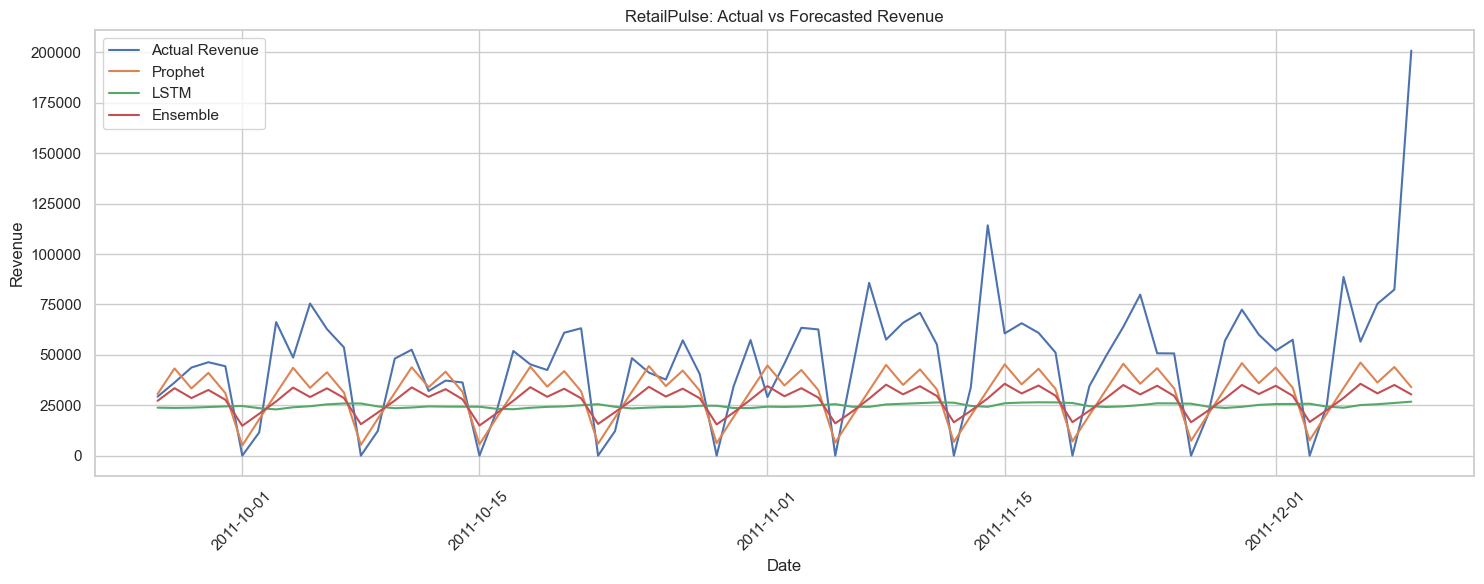

In [83]:
plt.figure(figsize=(15, 6))

plt.plot(
    ensemble_df["Date"],
    ensemble_df["ActualRevenue"],
    label="Actual Revenue"
)

plt.plot(
    ensemble_df["Date"],
    ensemble_df["Prophet_Forecast"],
    label="Prophet"
)

plt.plot(
    ensemble_df["Date"],
    ensemble_df["LSTM_Forecast"],
    label="LSTM"
)

plt.plot(
    ensemble_df["Date"],
    ensemble_df["Ensemble_Forecast"],
    label="Ensemble"
)

plt.title("RetailPulse: Actual vs Forecasted Revenue")
plt.xlabel("Date")
plt.ylabel("Revenue")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [84]:
ensemble_df.to_csv(
    OUTPUT_DIR / "day8_ensemble_forecast.csv",
    index=False
)

comparison.to_csv(
    OUTPUT_DIR / "day8_model_comparison.csv",
    index=False
)

print("Saved: day8_ensemble_forecast.csv")
print("Saved: day8_model_comparison.csv")

Saved: day8_ensemble_forecast.csv
Saved: day8_model_comparison.csv


#RetailPulse — Day 9: Churn Prediction and SHAP

Objectives:
- Create customer-level features.
- Define a proxy churn label using a time-based rule.
- Train a baseline classification model.
- Evaluate the model using classification metrics.
- Explain predictions using SHAP.
- Save the model, results, and feature importance.

In [86]:
import shap
import joblib

from pathlib import Path
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    average_precision_score
)

OUTPUT_DIR = Path("../outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Libraries imported successfully.")

Libraries imported successfully.


In [87]:
sales = pd.read_csv(
    OUTPUT_DIR / "day2_sales_data.csv",
    parse_dates=["InvoiceDate"]
)

print("Rows and columns:", sales.shape)
print("Date range:", sales["InvoiceDate"].min(),
      "to", sales["InvoiceDate"].max())

display(sales.head())

Rows and columns: (524878, 9)
Date range: 2010-12-01 08:26:00 to 2011-12-09 12:50:00


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34


In [88]:
sales = sales.dropna(
    subset=["CustomerID", "InvoiceNo", "InvoiceDate"]
).copy()

sales["CustomerID"] = sales["CustomerID"].astype(str)
sales["InvoiceDate"] = pd.to_datetime(sales["InvoiceDate"])

# Keep valid positive-value sales for this analysis
sales = sales[
    (sales["Quantity"] > 0) &
    (sales["UnitPrice"] > 0) &
    (~sales["InvoiceNo"].astype(str).str.startswith("C"))
].copy()

sales["Revenue"] = sales["Quantity"] * sales["UnitPrice"]

first_date = sales["InvoiceDate"].min()
last_date = sales["InvoiceDate"].max()

cutoff_date = first_date + (last_date - first_date) * 0.8

feature_sales = sales[sales["InvoiceDate"] < cutoff_date].copy()
outcome_sales = sales[sales["InvoiceDate"] >= cutoff_date].copy()

print("Feature window ends:", cutoff_date)
print("Feature-window rows:", len(feature_sales))
print("Outcome-window rows:", len(outcome_sales))

Feature window ends: 2011-09-25 21:33:12
Feature-window rows: 255052
Outcome-window rows: 137640


In [89]:
reference_date = cutoff_date

customer_features = feature_sales.groupby("CustomerID").agg(
    LastPurchase=("InvoiceDate", "max"),
    Frequency=("InvoiceNo", "nunique"),
    Monetary=("Revenue", "sum"),
    TotalQuantity=("Quantity", "sum"),
    AverageUnitPrice=("UnitPrice", "mean"),
    UniqueProducts=("StockCode", "nunique")
).reset_index()

customer_features["Recency"] = (
    reference_date - customer_features["LastPurchase"]
).dt.days

customer_features = customer_features.drop(
    columns=["LastPurchase"]
)

purchased_in_outcome = set(outcome_sales["CustomerID"].unique())

customer_features["ChurnProxy"] = (
    ~customer_features["CustomerID"].isin(purchased_in_outcome)
).astype(int)

print("Customer feature table:", customer_features.shape)
print("\nProxy churn distribution:")
display(
    customer_features["ChurnProxy"]
    .value_counts()
    .rename_axis("ChurnProxy")
    .to_frame("Customers")
)

display(customer_features.head())

Customer feature table: (3550, 8)

Proxy churn distribution:


,Customers
ChurnProxy,
0,1893
1,1657


,CustomerID,Frequency,Monetary,TotalQuantity,AverageUnitPrice,UniqueProducts,Recency,ChurnProxy
0,12346.0,1,77183.60,74215,1.040000,1,250,1
1,12347.0,5,2790.86,1590,2.797661,82,54,0
2,12348.0,4,1797.24,2341,5.764839,22,0,1
3,12350.0,1,334.40,197,3.841176,17,235,1
4,12352.0,6,1928.06,357,20.670179,40,5,0


In [90]:
feature_columns = [
    "Recency",
    "Frequency",
    "Monetary",
    "TotalQuantity",
    "AverageUnitPrice",
    "UniqueProducts"
]

X = customer_features[feature_columns].replace(
    [np.inf, -np.inf], np.nan
)

y = customer_features["ChurnProxy"]

valid_rows = X.notna().all(axis=1)

X = X.loc[valid_rows].reset_index(drop=True)
y = y.loc[valid_rows].reset_index(drop=True)

print("Feature matrix:", X.shape)
print("Churn classes:")
print(y.value_counts())
print("Churn rate:", round(y.mean() * 100, 2), "%")

Feature matrix: (3550, 6)
Churn classes:
ChurnProxy
0    1893
1    1657
Name: count, dtype: int64
Churn rate: 46.68 %


In [91]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

churn_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=8,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

churn_model.fit(X_train, y_train)

print("Baseline churn model trained.")

Baseline churn model trained.


Classification report:
              precision    recall  f1-score   support

           0       0.73      0.64      0.68       379
           1       0.64      0.73      0.68       331

    accuracy                           0.68       710
   macro avg       0.68      0.68      0.68       710
weighted avg       0.69      0.68      0.68       710

ROC-AUC: 0.7479
Average precision: 0.6891


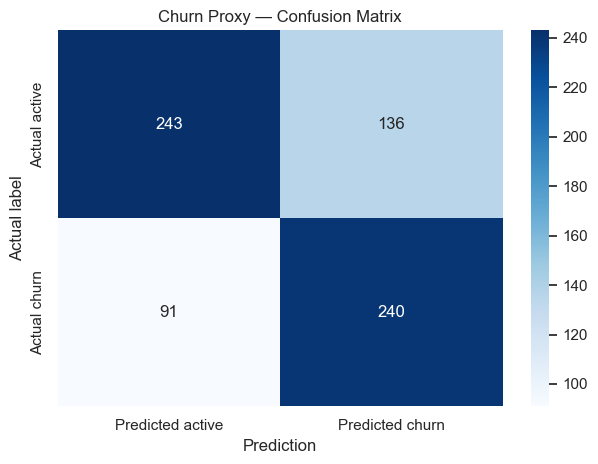

In [92]:
y_pred = churn_model.predict(X_test)
y_prob = churn_model.predict_proba(X_test)[:, 1]

print("Classification report:")
print(classification_report(y_test, y_pred, zero_division=0))

print("ROC-AUC:", round(roc_auc_score(y_test, y_prob), 4)
      if y_test.nunique() == 2 else "Not available: one test class")

print("Average precision:",
      round(average_precision_score(y_test, y_prob), 4)
      if y_test.nunique() == 2 else "Not available: one test class")

cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Predicted active", "Predicted churn"],
    yticklabels=["Actual active", "Actual churn"]
)

plt.title("Churn Proxy — Confusion Matrix")
plt.xlabel("Prediction")
plt.ylabel("Actual label")
plt.tight_layout()
plt.show()

In [93]:
explainer = shap.TreeExplainer(churn_model)

# Explain a manageable sample for speed
X_explain = X_test.head(min(200, len(X_test)))

shap_values = explainer.shap_values(X_explain)

print("SHAP explanation generated.")

SHAP explanation generated.


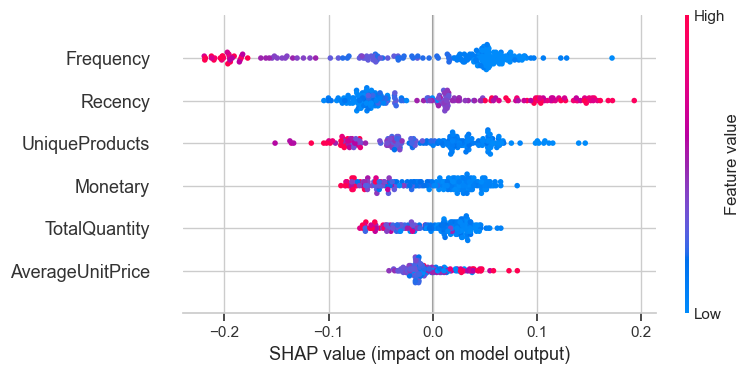

In [94]:
if isinstance(shap_values, list):
    # Older SHAP versions: one array per class
    values_for_churn = shap_values[1]
elif isinstance(shap_values, np.ndarray) and shap_values.ndim == 3:
    # Newer formats: samples x features x classes
    values_for_churn = shap_values[:, :, 1]
else:
    # Some versions return a two-dimensional array directly
    values_for_churn = shap_values

shap.summary_plot(
    values_for_churn,
    X_explain,
    feature_names=feature_columns,
    show=True
)

In [95]:
customer_features.to_csv(
    OUTPUT_DIR / "day9_customer_churn_features.csv",
    index=False
)

predictions = X_test.copy()
predictions["ActualChurnProxy"] = y_test.to_numpy()
predictions["PredictedChurnProxy"] = y_pred
predictions["ChurnRiskProbability"] = y_prob

predictions.to_csv(
    OUTPUT_DIR / "day9_churn_predictions.csv",
    index=False
)

importance = pd.DataFrame({
    "Feature": feature_columns,
    "Importance": churn_model.feature_importances_
}).sort_values("Importance", ascending=False)

importance.to_csv(
    OUTPUT_DIR / "day9_churn_feature_importance.csv",
    index=False
)

joblib.dump(
    churn_model,
    OUTPUT_DIR / "day9_churn_model.pkl"
)

print("Day 9 outputs saved successfully.")
display(importance)

Day 9 outputs saved successfully.


,Feature,Importance
1,Frequency,0.199258
2,Monetary,0.185310
0,Recency,0.180427
5,UniqueProducts,0.160787
3,TotalQuantity,0.160698
4,AverageUnitPrice,0.113521


# RetailPulse — Day 10: Inventory Optimization

Objectives:
- Analyze product-level sales demand.
- Estimate average daily demand and variability.
- Calculate safety stock and reorder points.
- Generate simulated inventory recommendations.
- Save inventory analysis outputs.

In [96]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

OUTPUT_DIR = Path("../outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

sales = pd.read_csv(
    OUTPUT_DIR / "day2_sales_data.csv",
    parse_dates=["InvoiceDate"]
)

print("Dataset shape:", sales.shape)
print("Date range:", sales["InvoiceDate"].min(),
      "to", sales["InvoiceDate"].max())

display(sales.head())

Dataset shape: (524878, 9)
Date range: 2010-12-01 08:26:00 to 2011-12-09 12:50:00


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34


In [97]:
sales = sales.dropna(
    subset=["StockCode", "InvoiceDate", "Quantity"]
).copy()

sales = sales[sales["Quantity"] > 0].copy()

sales["StockCode"] = sales["StockCode"].astype(str)
sales["Date"] = sales["InvoiceDate"].dt.normalize()

start_date = sales["Date"].min()
end_date = sales["Date"].max()

daily_demand = (
    sales.groupby(["StockCode", "Date"])["Quantity"]
    .sum()
    .unstack(fill_value=0)
)

all_dates = pd.date_range(start_date, end_date, freq="D")
daily_demand = daily_demand.reindex(
    columns=all_dates,
    fill_value=0
)

print("Products:", daily_demand.shape[0])
print("Calendar days:", daily_demand.shape[1])

display(daily_demand.iloc[:5, :7])

Products: 3922
Calendar days: 374


,2010-12-01,2010-12-02,2010-12-03,2010-12-04,2010-12-05,2010-12-06,2010-12-07
StockCode,,,,,,,
10002,60,1,8,0,1,25,8
10080,0,0,0,0,0,0,0
10120,0,0,3,0,0,0,0
10123C,0,0,1,0,0,0,0
10124A,0,0,0,0,0,4,0


In [98]:
LEAD_TIME_DAYS = 7
SERVICE_FACTOR = 1.65
REVIEW_PERIOD_DAYS = 1

product_stats = pd.DataFrame({
    "AverageDailyDemand": daily_demand.mean(axis=1),
    "DailyDemandStd": daily_demand.std(axis=1, ddof=1),
    "TotalUnitsSold": daily_demand.sum(axis=1),
    "SellingDays": (daily_demand > 0).sum(axis=1)
})

product_stats["DailyDemandStd"] = (
    product_stats["DailyDemandStd"].fillna(0)
)

product_stats = product_stats.reset_index()
product_stats = product_stats.rename(
    columns={"StockCode": "ProductCode"}
)

product_stats["SafetyStock"] = (
    SERVICE_FACTOR
    * product_stats["DailyDemandStd"]
    * np.sqrt(LEAD_TIME_DAYS)
).apply(np.ceil)

product_stats["ReorderPoint"] = (
    product_stats["AverageDailyDemand"] * LEAD_TIME_DAYS
    + product_stats["SafetyStock"]
).apply(np.ceil)

product_stats["TargetStockLevel"] = (
    product_stats["AverageDailyDemand"]
    * (LEAD_TIME_DAYS + REVIEW_PERIOD_DAYS)
    + product_stats["SafetyStock"]
).apply(np.ceil)

display(
    product_stats.sort_values(
        "TotalUnitsSold", ascending=False
    ).head(10)
)

,ProductCode,AverageDailyDemand,DailyDemandStd,TotalUnitsSold,SellingDays,SafetyStock,ReorderPoint,TargetStockLevel
2465,23843,216.564171,4188.151745,80995,1,18284.0,19800.0,20017.0
2020,23166,208.644385,3837.161108,78033,125,16752.0,18213.0,18422.0
1109,22197,152.133690,376.084089,56898,294,1642.0,2707.0,2860.0
2909,84077,146.927807,395.760222,54951,235,1728.0,2757.0,2904.0
3387,85099B,129.334225,180.200136,48371,300,787.0,1693.0,1822.0
3407,85123A,100.644385,223.737900,37641,305,977.0,1682.0,1783.0
439,21212,97.315508,172.511466,36396,298,754.0,1436.0,1533.0
3194,84879,97.224599,209.516404,36362,300,915.0,1596.0,1693.0
1942,23084,82.189840,280.584145,30739,136,1225.0,1801.0,1883.0
1374,22492,71.211230,164.357897,26633,208,718.0,1217.0,1288.0


In [99]:
product_names = (
    sales.dropna(subset=["StockCode"])
    .groupby("StockCode")["Description"]
    .agg(lambda x: x.mode().iloc[0] if not x.mode().empty
         else "Unknown product")
    .reset_index()
    .rename(columns={
        "StockCode": "ProductCode",
        "Description": "ProductDescription"
    })
)

product_stats = product_stats.merge(
    product_names,
    on="ProductCode",
    how="left"
)

display(
    product_stats[
        ["ProductCode", "ProductDescription",
         "AverageDailyDemand", "SafetyStock",
         "ReorderPoint", "TargetStockLevel"]
    ].head(10)
)

,ProductCode,ProductDescription,AverageDailyDemand,SafetyStock,ReorderPoint,TargetStockLevel
0,10002,INFLATABLE POLITICAL GLOBE,2.299465,52.0,69.0,71.0
1,10080,GROOVY CACTUS INFLATABLE,0.810160,19.0,25.0,26.0
2,10120,DOGGY RUBBER,0.513369,14.0,18.0,19.0
3,10123C,HEARTS WRAPPING TAPE,0.013369,1.0,2.0,2.0
4,10124A,SPOTS ON RED BOOKCOVER TAPE,0.042781,2.0,3.0,3.0
5,10124G,ARMY CAMO BOOKCOVER TAPE,0.045455,2.0,3.0,3.0
6,10125,MINI FUNKY DESIGN TAPES,3.462567,62.0,87.0,90.0
7,10133,COLOURING PENCILS BROWN TUBE,7.636364,85.0,139.0,147.0
8,10135,COLOURING PENCILS BROWN TUBE,5.959893,87.0,129.0,135.0
9,11001,ASSTD DESIGN RACING CAR PEN,4.318182,96.0,127.0,131.0


In [100]:
rng = np.random.default_rng(42)

product_stats["SimulatedStockOnHand"] = [
    int(rng.integers(0, max(2, int(target) + 1)))
    for target in product_stats["TargetStockLevel"]
]

product_stats["RecommendedOrderQuantity"] = (
    product_stats["TargetStockLevel"]
    - product_stats["SimulatedStockOnHand"]
).clip(lower=0)

product_stats["InventoryStatus"] = np.select(
    [
        product_stats["SimulatedStockOnHand"]
        <= product_stats["ReorderPoint"],
        product_stats["SimulatedStockOnHand"]
        > product_stats["TargetStockLevel"]
    ],
    [
        "Reorder",
        "Above target"
    ],
    default="Sufficient"
)

display(
    product_stats.sort_values(
        "RecommendedOrderQuantity", ascending=False
    ).head(15)
)

,ProductCode,AverageDailyDemand,DailyDemandStd,TotalUnitsSold,SellingDays,SafetyStock,ReorderPoint,TargetStockLevel,ProductDescription,SimulatedStockOnHand,RecommendedOrderQuantity,InventoryStatus
2465,23843,216.564171,4188.151745,80995,1,18284.0,19800.0,20017.0,"PAPER CRAFT , LITTLE BIRDIE",3913,16104.0,Reorder
2020,23166,208.644385,3837.161108,78033,125,16752.0,18213.0,18422.0,MEDIUM CERAMIC TOP STORAGE JAR,5580,12842.0,Reorder
1109,22197,152.133690,376.084089,56898,294,1642.0,2707.0,2860.0,POPCORN HOLDER,127,2733.0,Reorder
2909,84077,146.927807,395.760222,54951,235,1728.0,2757.0,2904.0,WORLD WAR 2 GLIDERS ASSTD DESIGNS,1010,1894.0,Reorder
1492,22616,69.836898,189.306828,26119,239,827.0,1316.0,1386.0,PACK OF 12 LONDON TISSUES,40,1346.0,Reorder
897,21915,58.564171,189.600766,21903,247,828.0,1238.0,1297.0,RED HARMONICA IN BOX,70,1227.0,Reorder
439,21212,97.315508,172.511466,36396,298,754.0,1436.0,1533.0,PACK OF 72 RETROSPOT CAKE CASES,609,924.0,Reorder
976,22053,11.347594,202.032878,4244,26,882.0,962.0,973.0,EMPIRE DESIGN ROSETTE,92,881.0,Reorder
367,21108,27.382353,231.204042,10241,137,1010.0,1202.0,1230.0,FAIRY CAKE FLANNEL ASSORTED COLOUR,388,842.0,Reorder
3017,84568,33.267380,166.430619,12442,106,727.0,960.0,994.0,GIRLS ALPHABET IRON ON PATCHES,214,780.0,Reorder


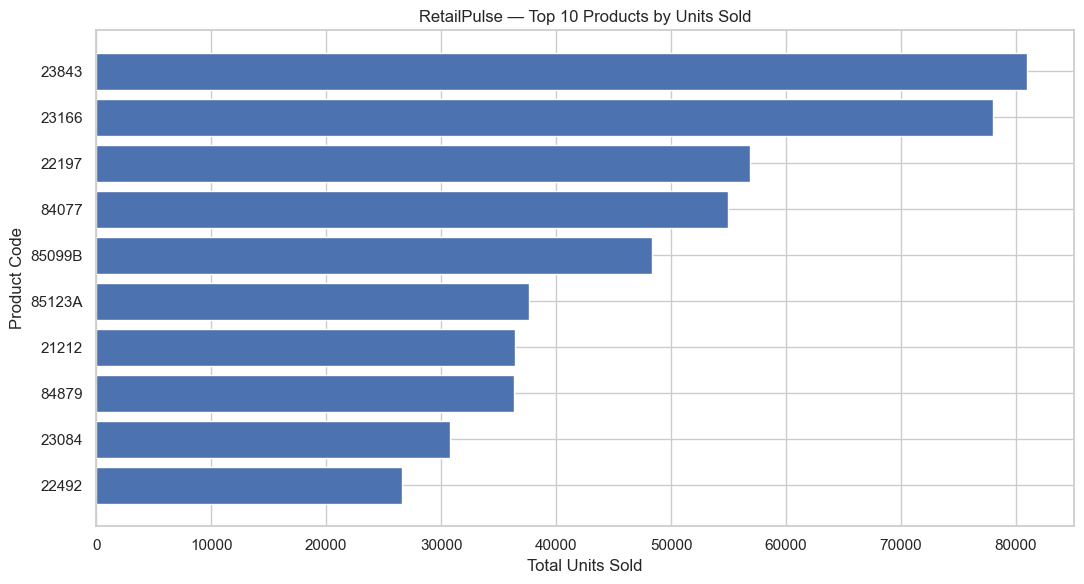

In [101]:
top_products = product_stats.nlargest(
    10, "TotalUnitsSold"
).sort_values("TotalUnitsSold")

plt.figure(figsize=(11, 6))
plt.barh(
    top_products["ProductCode"],
    top_products["TotalUnitsSold"]
)
plt.title("RetailPulse — Top 10 Products by Units Sold")
plt.xlabel("Total Units Sold")
plt.ylabel("Product Code")
plt.tight_layout()
plt.show()

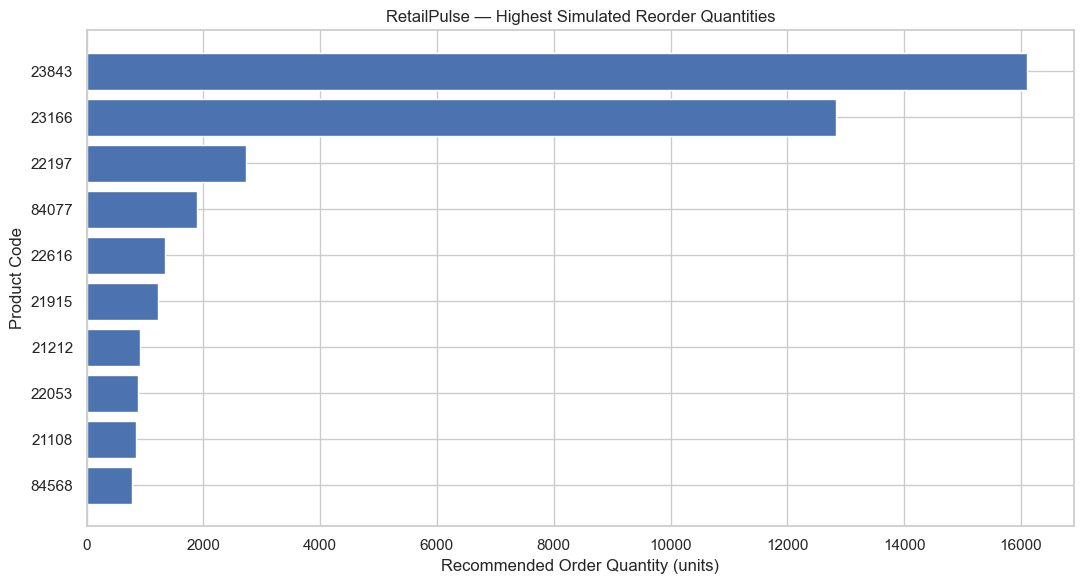

In [102]:
top_reorders = product_stats.nlargest(
    10, "RecommendedOrderQuantity"
).sort_values("RecommendedOrderQuantity")

plt.figure(figsize=(11, 6))
plt.barh(
    top_reorders["ProductCode"],
    top_reorders["RecommendedOrderQuantity"]
)
plt.title("RetailPulse — Highest Simulated Reorder Quantities")
plt.xlabel("Recommended Order Quantity (units)")
plt.ylabel("Product Code")
plt.tight_layout()
plt.show()

In [103]:
product_stats.to_csv(
    OUTPUT_DIR / "day10_inventory_recommendations.csv",
    index=False
)

daily_demand.reset_index().to_csv(
    OUTPUT_DIR / "day10_daily_product_demand.csv",
    index=False
)

print("Saved: day10_inventory_recommendations.csv")
print("Saved: day10_daily_product_demand.csv")

Saved: day10_inventory_recommendations.csv
Saved: day10_daily_product_demand.csv
